# Group 5 Machine Learning Project

**Group Members — Royce, Naufal, Hui Shin, Jun and Zhen Xiang**

**Main task** <br>
Predict whether a person earns more than USD \$50,000 a year, using Logistic Regression and XGBoost.

## 1. Introduction & Problem Formulation

**Data source [1]**

The dataset contains 48,842 records from the 1994 US Census database, with 14 original input features. It is publicly available at _**https://archive.ics.uci.edu/dataset/2/adult**_.

**Our project summary**

We use the **UCI Adult dataset** to predict whether a person's annual income is **more than USD \$50,000** or **less than or equal to USD \$50,000**, based on characteristics such as age, education level, occupation and working hours. This is **supervised binary classification** because the target has only two labels (>50K and ≤50K). We use **"0" for the ≤50K class (negative class)** and **"1" for the >50K class (positive class)**.

| Target value | Income class | Meaning in our metrics |
|:------------:|:------------:|:----------------------:|
| 0 | <=50K | Negative class (-) |
| 1 | >50K  | Positive class (+) |

#### Research question

Our group investigates **whether selecting fewer input features can keep or improve prediction performance, and whether XGBoost performs better than Logistic Regression**. This is a useful learning comparison between a simpler model that is easier to interpret (Logistic Regression) and a more flexible model (XGBoost) on real-world tabular data.

***However, these models are for educational purposes only. The dataset is based on historical US census data, so it may not represent present-day income patterns, especially in Singapore. The predictions should not be used for important real-world decisions, such as hiring, credit approval or eligibility assessments.***

_Note: XGBoost is **NOT** fully covered in the lecture materials, so we briefly explain how it works in our presentation slides._

#### Overview of what our code does

1. Reads the official tabular `.data` and `.test` files, adds column names and saves separate training and test CSV files.
2. Explores the **training data** with tables and charts.
3. Places missing categorical values into a separate **`Unknown`** category and uses **One-Hot Encoding** to turn categorical features into numbers.
4. Trains, validates and tunes **6 experiments** using **GridSearchCV** with the same stratified 5-fold cross-validation splits. For each experiment, GridSearchCV tests different hyperparameter settings and keeps the settings with the highest mean validation F1-score.
5. Compares the **best mean validation F1-scores** of all 6 experiments and selects the **best-performing experiment**. GridSearchCV has already retrained each experiment's best model on the full training dataset, so no further tuning or training is needed.
6. Tests **only the selected model** on the separate test dataset to measure its final performance. The test results are not used to change the model or its hyperparameters.
7. Shows which features were selected and which were most important, and compares prediction errors across demographic groups (e.g. does the model correctly identify more high-income males than high-income females?).

| Experiment No. | Model Type | Feature Selection |
|:--------------:|:--------------------|:-----------------|
| 1              | Logistic Regression | None (Control Experiment) |
| 2              | Logistic Regression | ANOVA F-statistic |
| 3              | Logistic Regression | Mutual Information |
| 4              | XGBoost             | None (Control Experiment) |
| 5              | XGBoost             | ANOVA F-statistic |
| 6              | XGBoost             | Mutual Information |

#### Before Running

Place `adult.data`, `adult.test` and `adult.names` in the same folder as this notebook. If any of these files are missing, **Section 1.3 will automatically download them from UCI**, as long as there is an internet connection. The original training and test datasets are kept separate. The notebook saves `adult_train.csv` and `adult_test.csv` in the same folder, so that they can be opened and previewed directly in JupyterLab.

**Software Requirements:** The required Python libraries must be installed before running the notebook. This notebook was tested with **scikit-learn 1.9.1** and **XGBoost 3.4.1**. The code also displays the installed software versions, so that others can repeat our results.

_Note: Small differences in results may occur when using different software versions or computers._

### 1.1 Install the required packages if needed

Running the cell below installs the required packages and skips any that are already installed at the right version. If it installs or updates anything, restart the kernel and run all cells again (Restart & Run All).

In [1]:
# scikit-learn and XGBoost are pinned to the versions we tested (the latest versions as of 14 November 2026).
# You may comment out the line below if these packages are already installed.
%pip install pandas numpy matplotlib seaborn scikit-learn==1.9.1 xgboost==3.4.1

Note: you may need to restart the kernel to use updated packages.


### 1.2 Load the tools

A library is a collection of ready-made functions. `pd`, `np`, `plt` and `sns` are short names for the libraries we use to work with tables, numbers and charts.

In [2]:
# Standard Python tools for copying settings, timing, paths and downloads.
from copy import deepcopy                # Makes a full, independent copy of an object.
from time import perf_counter           # Measures how long a piece of code takes to run.
from pathlib import Path                # Works with file and folder paths.
from urllib.request import urlretrieve  # Downloads a file from a web address.
import platform                         # Reports the Python version.
from packaging.version import Version  # Compares software version numbers correctly.

# Tools for tables, calculations and charts.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown  # Shows tables and formatted text in the notebook.

# Machine learning libraries.
import sklearn
import xgboost
from sklearn.base import clone  # Makes an unfitted copy of a model or preprocessor.

In [3]:
# Preprocessing tools learn how to fill gaps and turn categories into numbers.
from sklearn.compose import ColumnTransformer                        # Applies different preprocessing to numerical and categorical features
from sklearn.impute import SimpleImputer                             # For handling missing values
from sklearn.preprocessing import OneHotEncoder, StandardScaler      # One-hot encoding and Z-score scaling
from sklearn.pipeline import Pipeline                                # Ensures preprocessing, feature selection and model training happen in the correct order --> prevent data leakage during CV

# Feature selection keeps the highest-scoring encoded input columns.
from sklearn.feature_selection import SelectPercentile, f_classif, mutual_info_classif, VarianceThreshold     
# SelectPercentile used to choose the best features automatically
# VarianceThreshold removes features with zero variance


# Model selection compares settings using training data only.
from sklearn.model_selection import StratifiedKFold, GridSearchCV    # Stratified folds and hyperparameter search
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

# Metrics quantify correct predictions, mistakes and ranking quality.
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, roc_auc_score, confusion_matrix, make_scorer 
# make_scorer converts a metric function into a scorer that GridSearchCV can use.

In [4]:
RANDOM_STATE = 48  # Fixed seed for reproducible splits and random model steps.
N_FOLDS = 5         # Number of cross-validation folds.
THRESHOLD = 0.50    # Probability cutoff for the final class predictions.

# Record the software used for this run.
software_versions = pd.DataFrame({
    "Package": ["Python", "pandas", "numpy", "scikit-learn", "XGBoost"],
    "Version": [platform.python_version(), pd.__version__, np.__version__,
                sklearn.__version__, xgboost.__version__]
})
display(software_versions)

,Package,Version
0,Python,3.14.6
1,pandas,3.0.3
2,numpy,2.4.6
3,scikit-learn,1.9.1
4,XGBoost,3.4.1


### 1.3 Read the official documentation and data files

#### 1.3.1 Understand the source format

The Adult `.data` and `.test` files [1] are already **structured, comma-separated tables**, not unstructured text. Each row describes one adult, but the files have no column headings. `adult.names` describes the column order and explains that `?` means a missing value. The test file also starts with a note line, and each of its income labels ends with a full stop.

Below, we first look at the documentation and the first lines of each file, then read the tables with pandas.

In [5]:
# Use local copies when they exist. Download only files that are missing.
source_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/"

for filename in ["adult.data", "adult.test", "adult.names"]:

    # Path(filename).is_file() is True when the file already exists in this folder.
    if not Path(filename).is_file():
        print("Downloading:", filename)
        # try / except shows a clear message if the download fails (e.g. no internet).
        try:
            urlretrieve(source_url + filename, filename)
        except Exception as error:
            raise RuntimeError(
                "Could not download " + filename + ". Download the Adult files from UCI "
                "and place them beside this notebook, then rerun this cell."
            ) from error

# Read the official documentation without fitting or changing any model.
with open("adult.names", "r", encoding = "utf-8") as file:
    documentation = file.read()

print(documentation)

# Inspect the first two lines to see the original file format.
for filename in ["adult.data", "adult.test"]:
    print("\nFirst two lines of", filename)
    with open(filename, "r", encoding = "utf-8") as file:
        print(file.readline().strip())
        print(file.readline().strip())

| This data was extracted from the census bureau database found at
| http://www.census.gov/ftp/pub/DES/www/welcome.html
| Donor: Ronny Kohavi and Barry Becker,
|        Data Mining and Visualization
|        Silicon Graphics.
|        e-mail: ronnyk@sgi.com for questions.
| Split into train-test using MLC++ GenCVFiles (2/3, 1/3 random).
| 48842 instances, mix of continuous and discrete    (train=32561, test=16281)
| 45222 if instances with unknown values are removed (train=30162, test=15060)
| Duplicate or conflicting instances : 6
| Class probabilities for adult.all file
| Probability for the label '>50K'  : 23.93% / 24.78% (without unknowns)
| Probability for the label '<=50K' : 76.07% / 75.22% (without unknowns)
|
| Extraction was done by Barry Becker from the 1994 Census database.  A set of
|   reasonably clean records was extracted using the following conditions:
|   ((AAGE>16) && (AGI>100) && (AFNLWGT>1)&& (HRSWK>0))
|
| Prediction task is to determine whether a person makes over

In [6]:
# These names follow the exact left-to-right order in the source files.
column_names = [
    "age",
    "workclass",
    "fnlwgt",
    "education",
    "education-num",
    "marital-status",
    "occupation",
    "relationship",
    "race",
    "sex",
    "capital-gain",
    "capital-loss",
    "hours-per-week",
    "native-country",
    "income"
]

In [7]:
# Check that our explicit column list follows the official documentation.
# The feature definitions come after the line that lists the two income classes.
# split(..., 1)[1] keeps only the text that comes after that line.
feature_text = documentation.split(">50K, <=50K.", 1)[1]
documented_columns = []

# Each feature line starts with the feature name, followed by a colon and its description.
# Lines starting with | are comments in the documentation, so we skip them.
for line in feature_text.splitlines():
    if ":" in line and not line.strip().startswith("|"):
        feature_name = line.split(":", 1)[0].strip()
        documented_columns.append(feature_name)

# assert stops the notebook with an error message if the condition is False.
assert documented_columns + ["income"] == column_names, "Check the source column order."
print("Confirmed 14 original predictors and 1 income target.")

Confirmed 14 original predictors and 1 income target.


#### 1.3.2 Read the training data file

The training file has no column headings, so we add our column names and tell pandas to treat `?` as a missing value.

In [8]:
# Read the original training file into a table named train_df.
train_df = pd.read_csv(
    "adult.data",                 # Name of the training file.
    header = None,                # The original file has no column headings.
    names = column_names,         # Add the column names listed above.
    skipinitialspace = True,      # Ignore spaces immediately after commas.
    na_values = "?"               # Treat ? as a missing value.
)

# Display the first five rows to check that the table looks correct.
display(train_df.head())

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


#### 1.3.3 Read the test data file

We skip the first line of the test file because it is a note, not data. We also remove the full stop (.) at the end of each income label, so that the labels match the training file.

In [9]:
# Read the original test file into a separate table named test_df.
test_df = pd.read_csv(
    "adult.test",                 # Name of the test file.
    skiprows = 1,                 # Skip the note on the first line as it is a note.
    header = None,                # This file also has no column headings.
    names = column_names,         # Use the same column names as training.
    skipinitialspace = True,      # Ignore spaces immediately after commas.
    na_values = "?"               # Treat ? as a missing value.
)

# Make the test income labels match the training income labels.
test_df["income"] = test_df["income"].str.rstrip(".")   # right strip

# Check the first five rows after tidying the labels.
display(test_df.head())

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


In [10]:
# Check file structure and labels before creating model inputs.
assert train_df.shape == (32561, 15), "Unexpected training-file shape."
assert test_df.shape == (16281, 15), "Unexpected test-file shape."
assert set(train_df["income"].unique()) == {"<=50K", ">50K"}
assert set(test_df["income"].unique()) == {"<=50K", ">50K"}

# Store the text columns as general Python objects and mark missing values as np.nan.
# This keeps missing values working the same way in pandas 2 and pandas 3
# when they are passed to scikit-learn's SimpleImputer.
original_categorical_columns = [
    "workclass", "education", "marital-status", "occupation",
    "relationship", "race", "sex", "native-country"
]
for dataframe in [train_df, test_df]:
    dataframe[original_categorical_columns] = dataframe[original_categorical_columns].astype(object)
    dataframe[original_categorical_columns] = dataframe[original_categorical_columns].fillna(np.nan)

### 1.4 Save separate training and test CSV files

CSV is a plain-text table format that JupyterLab can preview directly. We save **two files** because one CSV file can only hold one table (it has no worksheets). Each file keeps all 14 original predictors, the target, the original row order and the missing values (saved as empty entries).

We continue to use `train_df` and `test_df` in memory, so the saved files are not read again. Saving them does not train any model or use the test data to make decisions.

In [11]:
# Save labelled CSV copies while keeping the original train/test split.
train_df.to_csv("adult_train.csv", index = False, encoding = "utf-8")
test_df.to_csv("adult_test.csv", index = False, encoding = "utf-8")

print("Training data (rows, columns):", train_df.shape)
print("Test data (rows, columns):", test_df.shape)
print("Saved adult_train.csv and adult_test.csv.")

Training data (rows, columns): (32561, 15)
Test data (rows, columns): (16281, 15)
Saved adult_train.csv and adult_test.csv.


## 2. Exploratory Data Analysis (EDA)

We only use the **training data** to make design choices. The test data is kept aside for the final evaluation. Reading and checking the test file above does not train a model or choose any settings.

### 2.1 Understand the columns and missing values

`info()` shows the data type and the number of non-missing values in each column. `describe()` summarises the numerical columns. The missing-value table shows which columns have gaps that we need to handle.

In [12]:
# ----------------------------------------------------------
# 1. Initial Data Checks
# ----------------------------------------------------------

# Use the training table already loaded above.

# Examine the data types and non-missing counts of each column.
print("Dataset Information:")
train_df.info()

# Summarise numerical features, including their mean, standard
# deviation, minimum and maximum values.
print("\nNumerical Summary Statistics:")
display(train_df.describe().T)

# Summarise categorical features, including the number of unique
# categories and the most frequently occurring value.
print("\nCategorical Summary Statistics:")
display(train_df[original_categorical_columns].describe().T)

# Identify missing values in each column.
# Calculate the percentage relative to the total training rows.
missing_count = train_df.isna().sum()

missing_summary = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing (%)': (missing_count / len(train_df) * 100).round(2)
})

print("\nColumns with Missing Values:")
display(missing_summary[missing_summary['Missing Count'] > 0])

# Count the number of records affected by at least one missing value.
missing_rows = train_df.isna().any(axis=1).sum()

print(f"\nRows with missing values: {missing_rows} "
      f"({missing_rows / len(train_df) * 100:.2f}%)")

# Check for exact duplicate rows across all columns.
print("\nExact Duplicate Rows:", train_df.duplicated().sum())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       30725 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education-num   32561 non-null  int64 
 5   marital-status  32561 non-null  object
 6   occupation      30718 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital-gain    32561 non-null  int64 
 11  capital-loss    32561 non-null  int64 
 12  hours-per-week  32561 non-null  int64 
 13  native-country  31978 non-null  object
 14  income          32561 non-null  str   
dtypes: int64(6), object(8), str(1)
memory usage: 3.9+ MB

Numerical Summary Statistics:


,count,mean,std,min,25%,50%,75%,max
age,32561.0,38.581647,13.640433,17.0,28.0,37.0,48.0,90.0
fnlwgt,32561.0,189778.366512,105549.977697,12285.0,117827.0,178356.0,237051.0,1484705.0
education-num,32561.0,10.080679,2.572720,1.0,9.0,10.0,12.0,16.0
capital-gain,32561.0,1077.648844,7385.292085,0.0,0.0,0.0,0.0,99999.0
capital-loss,32561.0,87.303830,402.960219,0.0,0.0,0.0,0.0,4356.0
hours-per-week,32561.0,40.437456,12.347429,1.0,40.0,40.0,45.0,99.0



Categorical Summary Statistics:


,count,unique,top,freq
workclass,30725,8,Private,22696
education,32561,16,HS-grad,10501
marital-status,32561,7,Married-civ-spouse,14976
occupation,30718,14,Prof-specialty,4140
relationship,32561,6,Husband,13193
race,32561,5,White,27816
sex,32561,2,Male,21790
native-country,31978,41,United-States,29170



Columns with Missing Values:


,Missing Count,Missing (%)
workclass,1836,5.64
occupation,1843,5.66
native-country,583,1.79



Rows with missing values: 2399 (7.37%)

Exact Duplicate Rows: 24


**Data Decision — Keeping Duplicate-Looking Rows**

We kept duplicate-looking rows because identical records may belong to different people. The dataset has no unique ID for each person (such as an NRIC number), so we cannot tell whether two identical rows are real duplicates. Removing them could throw away valid records and would change the original benchmark dataset.

However, if identical records appear in both the training and test data, the test results could be slightly too optimistic. We report how many such overlaps exist in Section 5.7.

### 2.2 Are the two income classes balanced?

A model can achieve high accuracy simply by always guessing the larger class. The table and chart below show how large this risk is.

In [13]:
# Count the number of records in each class
class_counts = train_df["income"].value_counts()  # Counts occurrences of each class

# Create a table showing the count and percentage
class_table = pd.DataFrame({
    "Count": class_counts,
    "Percentage (%)": (class_counts / len(train_df) * 100).round(2)
})

display(class_table)

,Count,Percentage (%)
income,,
<=50K,24720,75.92
>50K,7841,24.08


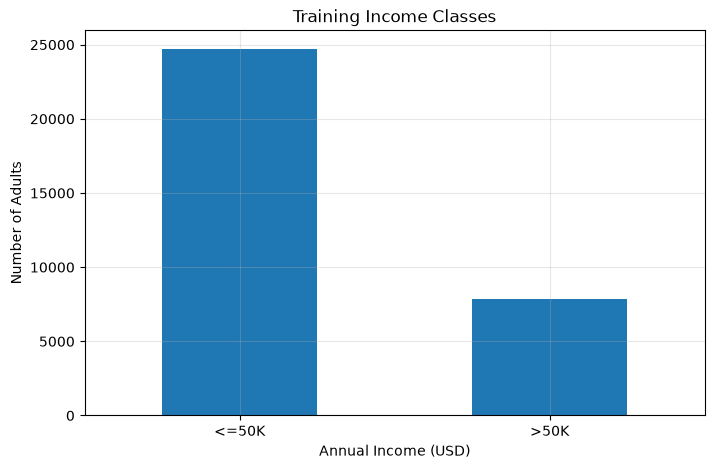

In [14]:
train_df["income"].value_counts().plot(
    kind = "bar",
    figsize = (8, 5),
    title = "Training Income Classes",
    xlabel = "Annual Income (USD)",
    ylabel = "Number of Adults",
    rot = 0                         # Keep the x-axis labels horizontal (0 degrees).
)
plt.grid(alpha = 0.3)
plt.show()

**Results:**

The bar chart shows that the ≤50K class has many more records than the >50K class, so the data has **a class imbalance**.

Our main evaluation metric is the **F1-score for the >50K class**, because our goal is to identify people who earn more than USD 50,000. Since >50K is also the smaller class, accuracy alone can be misleading. F1-score balances precision and recall, so it shows how well the model finds people who earn more than USD 50,000.

### 2.3 Explore distributions and potential outliers

We look at the distributions of age, education level and working hours to understand the data and spot potential outliers. We also look at how these features relate to income. However, a relationship in the data does not prove that one thing causes the other.

*We focus on these features to keep our analysis short while still covering features that are likely to matter for income.*

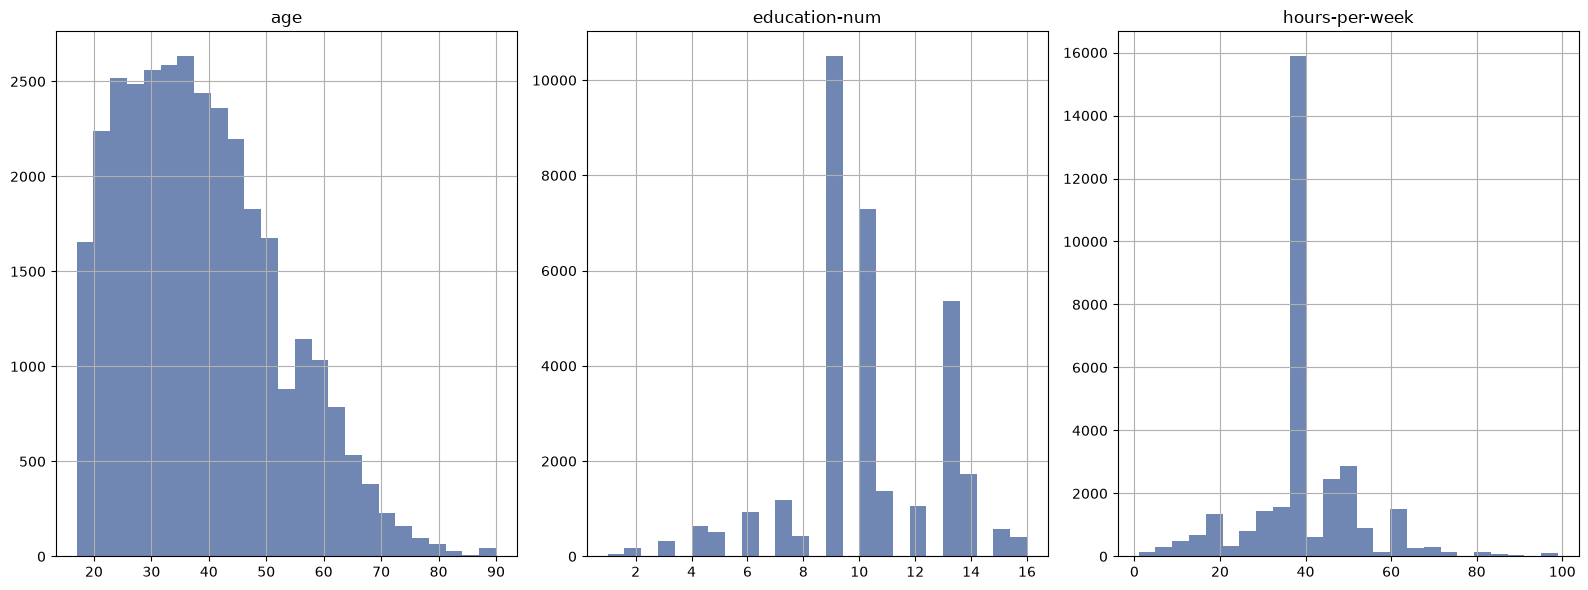

In [15]:
# Explore the distributions of age, education and working hours
train_df[["age", "education-num", "hours-per-week"]].hist(
    bins = 25,
    figsize = (16, 6),
    layout = (1, 3),          # 1 row, 3 columns (3 histograms in 1 row)
    color = "#7187B3"
)

plt.tight_layout()
plt.show()

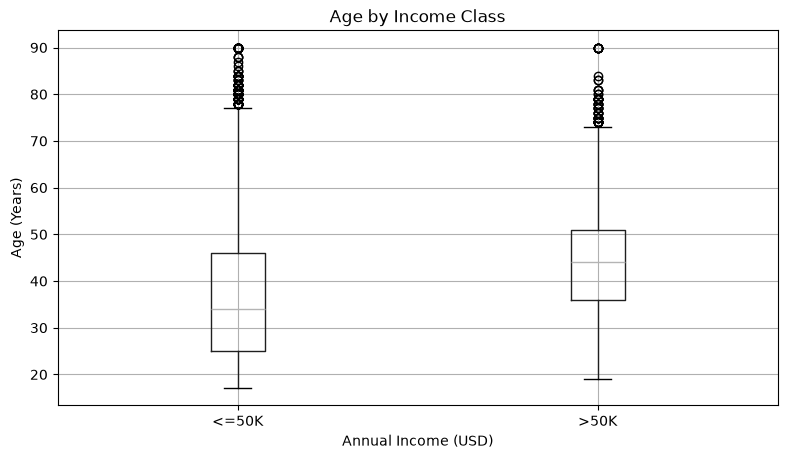

In [16]:
# Compare age between income classes
train_df.boxplot(
    column = "age",
    by = "income",
    figsize = (9, 5)
)

plt.suptitle("")  # Remove the overall title of the entire figure
plt.title("Age by Income Class")
plt.xlabel("Annual Income (USD)")
plt.ylabel("Age (Years)")
plt.show()

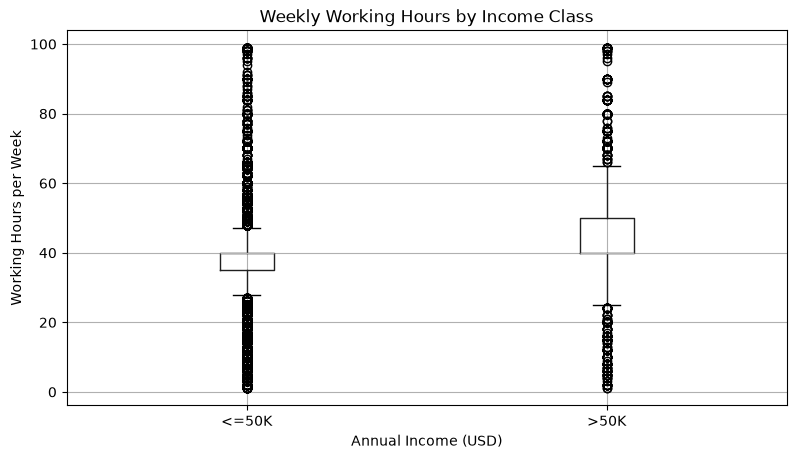

In [17]:
# Compare working hours between income classes
train_df.boxplot(
    column = "hours-per-week",
    by = "income",
    figsize = (9, 5)
)

plt.suptitle("") # Remove the overall title of the entire figure
plt.title("Weekly Working Hours by Income Class")
plt.xlabel("Annual Income (USD)")
plt.ylabel("Working Hours per Week")
plt.show()

#### 2.3.1 Explore capital gains and capital losses

**What are capital gains and capital losses?**

Capital gains and losses are the profits and losses made from selling assets, such as stocks or property. We explore them because they may help to predict a person's income class. We also check their distributions for potential outliers.

In [18]:
# Examine capital gain and capital loss
capital_columns = ["capital-gain", "capital-loss"]

capital_summary = train_df[capital_columns].describe(percentiles = [0.25, 0.5, 0.75, 0.9, 0.99]).T  # .T transposes the DataFrame

capital_summary["Zero (%)"] = (train_df[capital_columns] == 0).mean() * 100  # Calculate the percentage of zero values

display(capital_summary.round(2))

,count,mean,std,min,25%,50%,75%,90%,99%,max,Zero (%)
capital-gain,32561.0,1077.65,7385.29,0.0,0.0,0.0,0.0,0.0,15024.0,99999.0,91.67
capital-loss,32561.0,87.30,402.96,0.0,0.0,0.0,0.0,0.0,1980.0,4356.0,95.33


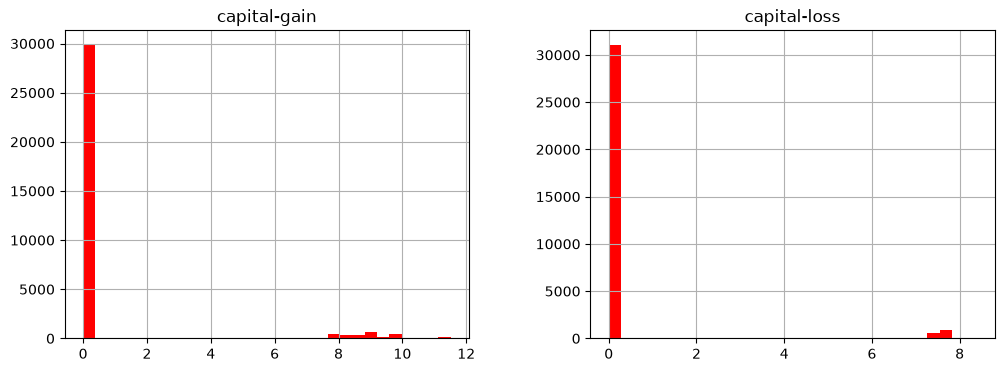

In [19]:
# Apply logarithmic transformation to reduce right-skewness for visualisation.
np.log1p(train_df[capital_columns]).hist(
    bins = 30,
    figsize = (12, 4),
    layout = (1, 2),
    color = "#FF0000"
)

plt.show()

#### 2.3.2 Examine the non-zero capital values

The histograms above show that most people have zero capital gains and zero capital losses. Even after the logarithmic transformation, most values are still stacked at zero, which makes the non-zero values hard to see.

Therefore, we plot only the non-zero values to understand their distributions and look for potential outliers.

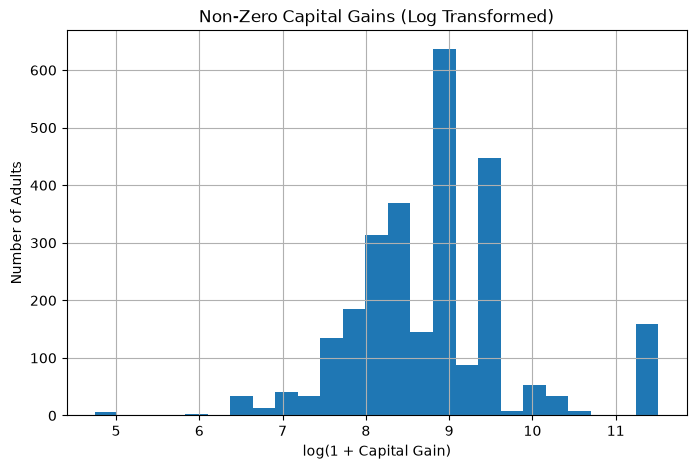

In [20]:
# Explore the distribution of non-zero capital gains
np.log1p(train_df.loc[train_df["capital-gain"] > 0, "capital-gain"]).hist(
    bins = 25,
    figsize = (8, 5)
)

plt.title("Non-Zero Capital Gains (Log Transformed)")
plt.xlabel("log(1 + Capital Gain)")
plt.ylabel("Number of Adults")
plt.show()

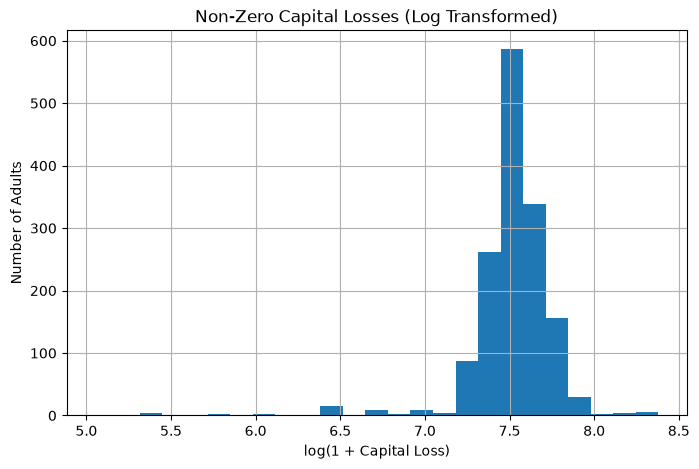

In [21]:
# Explore the distribution of non-zero capital losses
np.log1p(train_df.loc[train_df["capital-loss"] > 0, "capital-loss"]).hist(
    bins = 25,
    figsize = (8, 5)
)

plt.title("Non-Zero Capital Losses (Log Transformed)")
plt.xlabel("log(1 + Capital Loss)")
plt.ylabel("Number of Adults")
plt.show()

#### 2.3.3 Decide how to handle potential outliers

We decided to keep outliers because unusually high values are not necessarily mistakes. For example, some people genuinely work very long hours or have large capital gains. These records may help the model predict income.

For Logistic Regression, we later use StandardScaler to rescale the inputs. This helps the model train well, but it does not remove outliers, so unusually high or low values can still affect the predictions.

### 2.4 Compare education and occupation with income

The charts below compare **percentages within each category**, so large categories do not dominate just because they contain more people. Missing values are shown as `Unknown`, which is the same label our models use for missing values later (Section 3.3).

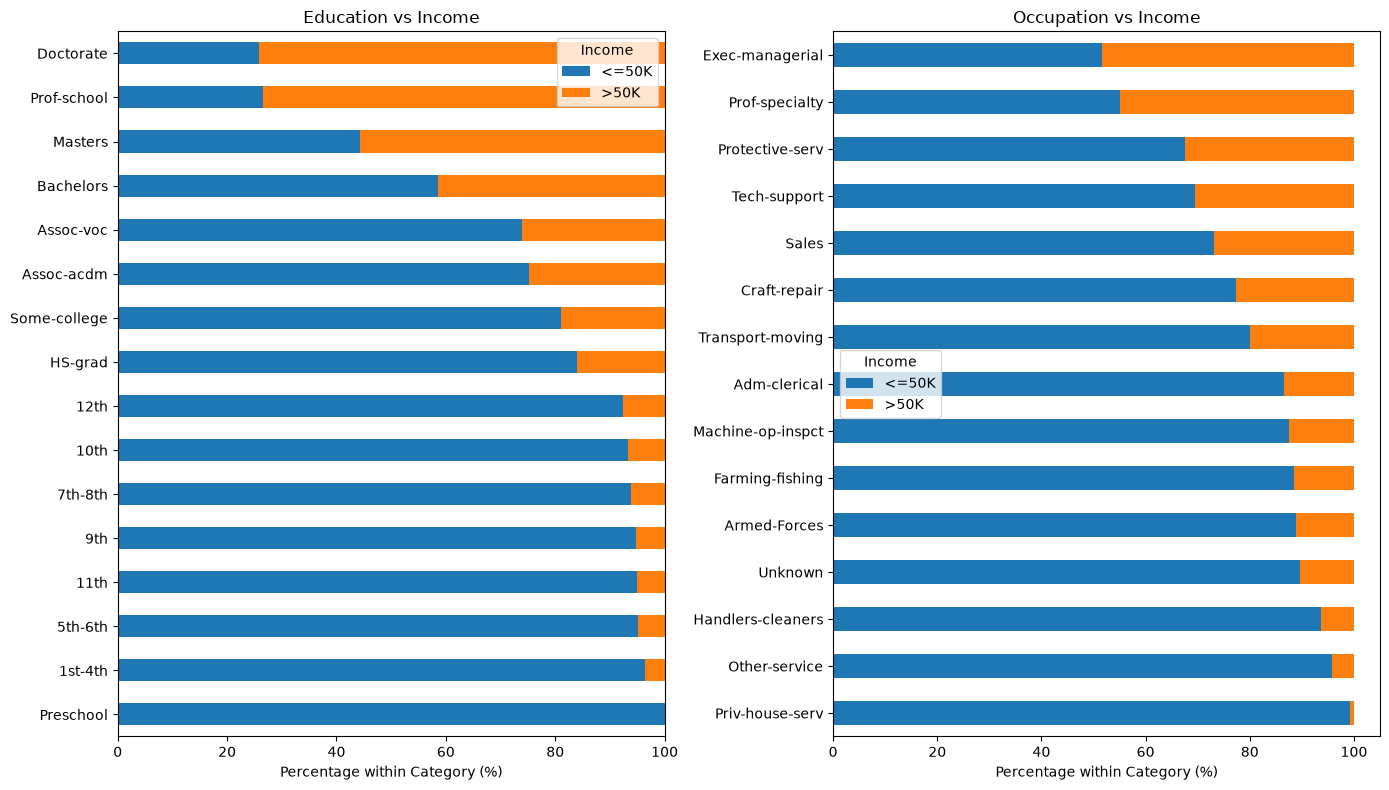

In [22]:
# Compare income proportions within education and occupation groups.

# Compare income percentages within each category instead
# of raw counts, since category sizes differ.
fig, axes = plt.subplots(1, 2, figsize=(14, 8))

for ax, column, title in [
    (axes[0], 'education', 'Education vs Income'),
    (axes[1], 'occupation', 'Occupation vs Income')
]:
    # Show missing values as "Unknown", the same label our models use later (Section 3.3).
    categories = train_df[column].fillna('Unknown')

    # crosstab() counts people in each category and income class.
    # normalize = 'index' turns each row into proportions that add up to 1.
    income_percent = pd.crosstab(
        categories,
        train_df['income'],
        normalize='index'
    ) * 100

    # Sort categories by their percentage of higher earners.
    income_percent = income_percent.sort_values('>50K')

    income_percent.plot(
        kind='barh',
        stacked=True,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel('Percentage within Category (%)')
    ax.set_ylabel('')
    ax.legend(title='Income')

plt.tight_layout()
plt.show()

Next, we check whether people with a missing value earn differently from everyone else. If they do, the fact that a value is missing is useful information, and we should keep it instead of hiding it.

In [23]:
# Compare the percentage of >50K earners in rows with and without a missing value.
# This helps us decide how to handle missing values in Section 3.3.
missing_check_rows = []

for column in ["workclass", "occupation", "native-country"]:

    # True if the value in this column is missing, False otherwise.
    is_missing = train_df[column].isna()

    # (train_df["income"] == ">50K") gives True or False for each person.
    # .mean() of True/False values gives the proportion of True values.
    # ~ means NOT, so ~is_missing selects the rows that are not missing.
    missing_check_rows.append({
        "Feature": column,
        "Missing Rows": is_missing.sum(),
        ">50K among Missing (%)": (train_df.loc[is_missing, "income"] == ">50K").mean() * 100,
        ">50K among Not Missing (%)": (train_df.loc[~is_missing, "income"] == ">50K").mean() * 100
    })

missing_check = pd.DataFrame(missing_check_rows)
display(missing_check.round(2))

,Feature,Missing Rows,>50K among Missing (%),>50K among Not Missing (%)
0,workclass,1836,10.40,24.90
1,occupation,1843,10.36,24.90
2,native-country,583,25.04,24.06


### 2.5 EDA findings and interpretation

**Dataset overview:** <br>
The training table has **32,561 rows**, six numerical and eight categorical input features, and one target. There are **24 duplicate-looking rows**, and **2,399 rows (7.37%)** contain at least one missing value. Ages range from 17 to 90, and working hours range from 1 to 99 per week (Section 2.1).

**Missing values:** <br>
`occupation` has **1,843** missing values, `workclass` has **1,836** and `native-country` has **583** (Section 2.1). Only about **10%** of people with a missing `workclass` or `occupation` earn >50K, compared with about **25%** of people whose value is not missing (Section 2.4). This means that a missing value in these columns carries useful information. Instead of removing these rows or filling the gaps with the most common category, we place them in a separate **`Unknown`** category (Section 3.3). For `native-country`, people with a missing value earn >50K about as often as everyone else. The numerical features have no missing values, but we still include a numerical imputer as a safety step.

**Class balance:** <br>
The training data contains 24,720 adults earning ≤50K and 7,841 adults earning >50K, which is about 76% and 24%. The data is imbalanced, so accuracy alone is not enough to evaluate our models (Section 2.2).

**Age and working hours:** <br>
Adults earning >50K tend to be older, with a median age of 44 compared with 34 for those earning ≤50K. Both income groups have a median of 40 working hours per week. The two groups overlap a lot, which suggests that **age and working hours may help to predict income** but cannot separate the two classes on their own (Section 2.3).

**Capital gains and losses:** <br>
About 91.67% of `capital-gain` values and 95.33% of `capital-loss` values are zero, so both features are highly skewed. Even after a logarithmic transformation, most values remain at zero, so we also looked at the non-zero values separately (Sections 2.3.1 and 2.3.2).

**Outliers:** <br>
The boxplots show potential outliers. We kept them because unusually high or low values may be genuine and useful for predicting income (Section 2.3.3).

**Education and occupation:** <br>
Higher education levels and professional or managerial occupations contain larger percentages of >50K earners (Section 2.4).

Overall, our EDA suggests that several features may be useful for predicting income. However, these are associations in the data and do not prove that a characteristic causes higher income.

## 3. Data Preprocessing

### 3.1 Decide the inputs and preserve the original split

We keep the original UCI training and test datasets. Instead of creating a separate validation set, we use **five-fold cross-validation within the training dataset**. The test set is kept aside until the feature-selection settings, hyperparameters and final model have all been chosen.

| Excluded feature | Reason |
|:---------------:|:-----|
| `sex`, `race` | These are sensitive demographic characteristics. Removing them stops our models from directly using sex or race to predict income and aims to reduce potential demographic bias. However, this does not guarantee fairness, because other features, such as `relationship`, may indirectly reveal a person's sex. |
| `fnlwgt` | This is a survey weight used to estimate population totals. It does not describe the person. Since our project predicts each person's income from their own characteristics, we exclude it. |

The remaining 11 features, including age, education, education-num, occupation and capital-gain, are kept and passed to automatic feature selection.

**We believe that income predictions should not directly depend on a person's sex or race. Excluding these sensitive features is one step towards reducing potential discrimination in our models, although it does not guarantee completely unbiased predictions.**

`income` is the target we are predicting, so it is stored separately as `y` instead of being one of the inputs in `X`.

In [24]:
# These are the only three predictors we manually exclude.
excluded_features = ["sex", "race", "fnlwgt"]

# X contains the predictors. income is kept separately because it is the answer.
# drop() returns a new table, so train_df still contains all the original columns.
X_train = train_df.drop(columns = ["income"] + excluded_features)

# True becomes 1 and False becomes 0 when converted to integers.
# Therefore, >50K is our positive class (1) and <=50K is our negative class (0).
y_train = (train_df["income"] == ">50K").astype(int)   # True becomes 1 and False becomes 0.

# Store the retained column names as a Python list so the test set uses the exact same inputs later.
feature_columns = X_train.columns.tolist()

print("Number of original predictors retained:", X_train.shape[1])
print("Retained predictors:", feature_columns)

Number of original predictors retained: 11
Retained predictors: ['age', 'workclass', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country']


In [25]:
# Show the first five rows of the model inputs.
display(X_train.head())

,age,workclass,education,education-num,marital-status,occupation,relationship,capital-gain,capital-loss,hours-per-week,native-country
0,39,State-gov,Bachelors,13,Never-married,Adm-clerical,Not-in-family,2174,0,40,United-States
1,50,Self-emp-not-inc,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,0,0,13,United-States
2,38,Private,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,0,0,40,United-States
3,53,Private,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,0,0,40,United-States
4,28,Private,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,0,0,40,Cuba


### 3.2 Prepare numerical and categorical columns

The lists below tell the preprocessor how to handle each column that we kept.

| Treatment | Features |
|:---------:|:--------:|
| Numerical inputs | `age`, `education-num`, `capital-gain`, `capital-loss`, `hours-per-week` |
| Categories to one-hot encode | `workclass`, `education`, `marital-status`, `occupation`, `relationship`, `native-country` |

We use **one-hot encoding** for the categorical features, as covered in the lectures. Logistic Regression needs numbers as inputs, and one-hot encoding turns each category into its own column of 0s and 1s. We use the same encoding for XGBoost, so that both models receive the same inputs.

In [26]:
# Keep this order. The numerical columns appear first after preprocessing,
# and the MI function in Section 3.4 uses these positions to find them.
numeric_features = [
    "age",
    "education-num",
    "capital-gain",
    "capital-loss",
    "hours-per-week"
]

# These columns contain text categories, which need to be converted into numbers.
categorical_features = [
    "workclass",
    "education",
    "marital-status",
    "occupation",
    "relationship",
    "native-country"
]

print("No. of numerical features:", len(numeric_features))
print("No. of categorical features:", len(categorical_features))
print("Total:", len(numeric_features) + len(categorical_features))

No. of numerical features: 5
No. of categorical features: 6
Total: 11


### 3.3 Fill missing values and one-hot encode categories

#### 3.3.1 Fill missing values

We handle missing values with **imputation**, which means filling each gap with a replacement value.

| Feature type | What we do | Why |
|:---:|:---|:---|
| Numerical | Replace a missing value with the **median** of that column | The median is not pulled up or down by outliers. Our numerical columns have no missing values, so this is only a safety step. |
| Categorical | Replace a missing value with the word **`Unknown`** | People with a missing `workclass` or `occupation` earn >50K much less often than others (Section 2.4). Giving them their own `Unknown` category lets the model learn this pattern instead of hiding it. |

The median is calculated using only the training part of each cross-validation fold, so no information leaks from the validation rows. `Unknown` is a fixed word, so it does not need to be learned from the data.

After imputation, one-hot encoding turns `Unknown` into its own column, for example `occupation_Unknown`. A value of 1 in that column means that the person's occupation was missing.

#### 3.3.2 Understand one-hot encoding

For example, suppose `education` only has 3 categories, `HS-grad`, `Bachelors` and `Masters`. One-hot encoding creates one column for each category.

| `education_HS-grad` | `education_Bachelors` | `education_Masters` |
|:-------------------:|:---------------------:|:-------------------:|
| 1 | 0 | 0 |
| 0 | 1 | 0 |
| 0 | 0 | 1 |

Each row represents a person. A value of 1 means that the person belongs to that category, and 0 means that they do not.

*This is only an illustration and does **NOT** show the real dataset.*

#### 3.3.3 Understand the preprocessing terms

- **handle_unknown = "ignore"**: Prevents errors when the validation or test dataset contains a category that was not present during training. Such categories are represented by "0" in all the one-hot encoded columns of that feature. (This is different from our `Unknown` category for missing values.)

- **sparse_output = False**: Stores the one-hot encoded results as a regular NumPy array instead of a compressed sparse matrix to ensure compatibility with functions such as StandardScaler() and our feature-selection code.

- **ColumnTransformer**: Helps decide how different columns should be processed, allowing numerical and categorical features to undergo different preprocessing steps.

- **Pipeline**: Ensures that preprocessing, feature selection and model training happen in the correct order. It also prevents data leakage during cross-validation by learning preprocessing values using only the training portion of each fold.

In 5-fold cross-validation, the preprocessing is learned from 4 folds and then applied to the remaining validation fold. This is repeated 5 times.

`education-num` stays numerical. When we calculate Mutual Information, we treat it as a discrete feature because it only has a small number of ordered education levels. This does **not** mean that it is one-hot encoded. We keep both `education` and `education-num`, although they contain overlapping information (see Section 5.9).

In [27]:
# OneHotEncoder renamed sparse to sparse_output in scikit-learn 1.2.
# Both branches produce the same dense output format.
# Version() compares version numbers correctly (e.g. 1.10 is newer than 1.9).
if Version(sklearn.__version__) >= Version("1.2"):
    category_encoder = OneHotEncoder(handle_unknown = "ignore", sparse_output = False)
else:
    category_encoder = OneHotEncoder(handle_unknown = "ignore", sparse = False)

In [28]:
# Pipeline applies its steps in the listed order.
# General workflow is Fill missing values → One-hot encode → Feature selection (if applicable) → Train model

# Fill in missing values in numerical columns using the median.
numeric_preprocessor = Pipeline(
    steps = [
        ("imputer", SimpleImputer(strategy = "median"))
    ]
)

# Fill missing categories with the word "Unknown", then perform one-hot encoding.
# "Unknown" becomes its own category, so people with missing values get their own
# one-hot column (e.g. occupation_Unknown) and the model can learn from it.
categorical_preprocessor = Pipeline(
    steps = [
        ("imputer", SimpleImputer(strategy = "constant", fill_value = "Unknown")),
        ("onehot", category_encoder)
    ]
)

# Apply the appropriate preprocessing to each group of features.
preprocessor = ColumnTransformer(
    transformers = [
        ("numeric", numeric_preprocessor, numeric_features),                # numeric is the name for this group of preprocessing steps
        ("category", categorical_preprocessor, categorical_features)        # category is the name for this group of preprocessing steps
    ], verbose_feature_names_out = False  # Removes automatically added prefixes such as "numeric__" from feature names when preprocessing (i.e. remove "numeric__age")
)

### 3.4 Understand the feature-selection methods

ANOVA F-statistic and Mutual Information (MI) are both **filter** methods. They score and rank each encoded feature on its own, based on its relationship with income, before any model is trained. Unlike wrapper methods such as forward selection, they do not repeatedly train models to test different combinations of features.

| Method | Explanation |
|:------:|-------------|
| None   | (Control experiment) Keeps all encoded features, except constant columns that are removed later. This lets us check whether feature selection actually helps. |
| ANOVA F-statistic | Ranks features by how much their average value differs between the two income classes, compared with the variation inside each class. A higher F-statistic means a bigger difference between the classes. |
| Mutual Information (MI) | Ranks features by how much information they give about a person's income class. Unlike the ANOVA F-statistic, MI can also detect nonlinear relationships. |

For both ANOVA and MI, we use `SelectPercentile` to rank the encoded features and keep the highest-scoring 25%, 50% or 75%. Cross-validation compares these percentages in Section 4.

*Note on p-values: ANOVA also calculates a p-value. A p-value measures how surprising our F-statistic (or a more extreme one) would be if the null hypothesis (H0) were true, where H0 says that both income classes have the same mean. A smaller p-value gives stronger evidence against H0. However, we only use the F-statistics to rank features, not the p-values to test statistical significance. \[Recall ENG3100 Data Analytics and Visualisation].*

#### 3.4.1 Understand the two scoring functions

- **`calculate_mutual_information()`** tells MI which features are discrete (a small set of values or categories) and which are continuous (numerical measurements), so that MI can score them correctly.
- **`calculate_anova_scores()`** gives an F-score of 0 to any feature with a constant value (no variation), which avoids calculation errors and warnings.

In [29]:
# Calculate Mutual Information scores for each feature.
def calculate_mutual_information(X_values, y_values):

    # True = discrete feature, False = continuous feature.
    # Initially, treat all features as discrete.
    # shape[1] gives the total number of columns (features).
    discrete_columns = [True] * X_values.shape[1]

    # Use the continuous MI estimator for these numerical measurements.
    # They are stored as whole numbers, but we treat them as continuous measurements (our modelling choice).
    gain_position = numeric_features.index("capital-gain")
    loss_position = numeric_features.index("capital-loss")
    hours_position = numeric_features.index("hours-per-week")
    age_position = numeric_features.index("age")

    # Treat these four columns as continuous for MI estimation.
    # education-num and the one-hot indicators remain discrete.
    discrete_columns[gain_position] = False
    discrete_columns[loss_position] = False
    discrete_columns[hours_position] = False
    discrete_columns[age_position] = False

    # Calculate the MI score for each feature.
    scores = mutual_info_classif(
        X_values,
        y_values,
        discrete_features = discrete_columns,
        random_state = RANDOM_STATE
    )

    return scores

In [30]:
# Calculate ANOVA F-statistics for each feature.
def calculate_anova_scores(X_values, y_values):

    # Initially, assign every feature an F-score of 0.
    # shape[1] gives the total number of features.
    scores = np.zeros(X_values.shape[1])

    # Check which features have different values (not constant).
    # np.ptp() calculates maximum - minimum for each column.
    # axis = 0 means we calculate this for each column.
    varying_columns = np.ptp(X_values, axis = 0) > 0

    # Calculate F-statistics only for features that are not constant.
    # X_values[:, varying_columns] keeps every row but only the varying columns.
    if not varying_columns.any():
        return scores  # No useful ranking is possible if every column is constant.

    f_scores, p_values = f_classif(X_values[:, varying_columns], y_values)

    # Store the calculated F-scores in their corresponding positions.
    # Replace any undefined scores (NaN) with 0.
    # Constant features will retain their original score of 0.
    scores[varying_columns] = np.nan_to_num(f_scores, nan = 0.0)

    # Return the F-scores for feature ranking.
    # We do not use the p-values for feature selection.
    return scores

#### 3.4.2 Explore the feature rankings using training data

The code below ranks the encoded columns using the full training data. It shows the top 15 columns for each method and how many appear in both lists. This is only to illustrate the two methods. These rankings are **not reused** during cross-validation. Inside GridSearchCV, the encoder and the feature selector are fitted again on every training fold.

In [31]:
# ----------------------------------------------------------
# Illustrative Feature Ranking (training data only)
# ----------------------------------------------------------
# This exploration does not feed its feature ranking into model training.
# clone() makes a fresh, unfitted copy of the preprocessor.
feature_inspection_encoder = clone(preprocessor)

# fit_transform() learns the encoding from the training data and applies it.
X_ranked = feature_inspection_encoder.fit_transform(X_train)
encoded_names = feature_inspection_encoder.get_feature_names_out()

# Score every encoded column with both methods.
anova_scores = calculate_anova_scores(X_ranked, y_train)
mi_scores = calculate_mutual_information(X_ranked, y_train)

feature_ranking = pd.DataFrame({
    'Encoded feature': encoded_names,
    'ANOVA F-score': anova_scores,
    'MI score': mi_scores
})

# nlargest(15, ...) keeps the 15 rows with the highest scores.
anova_top = feature_ranking.nlargest(15, 'ANOVA F-score')['Encoded feature'].tolist()
mi_top = feature_ranking.nlargest(15, 'MI score')['Encoded feature'].tolist()

print('Top 15 ANOVA features:')
display(feature_ranking.nlargest(15, 'ANOVA F-score')[['Encoded feature', 'ANOVA F-score']].round(4))
print('Top 15 MI features:')
display(feature_ranking.nlargest(15, 'MI score')[['Encoded feature', 'MI score']].round(4))
# set(a) & set(b) keeps only the names that appear in both lists.
print('Features appearing in both top-15 lists:', len(set(anova_top) & set(mi_top)))

Top 15 ANOVA features:


,Encoded feature,ANOVA F-score
32,marital-status_Married-civ-spouse,8025.8421
52,relationship_Husband,6240.0183
1,education-num,4120.0958
34,marital-status_Never-married,3674.2001
0,age,1886.7073
4,hours-per-week,1813.3863
55,relationship_Own-child,1794.1575
2,capital-gain,1709.1501
40,occupation_Exec-managerial,1575.8484
53,relationship_Not-in-family,1199.4813


Top 15 MI features:


,Encoded feature,MI score
32,marital-status_Married-civ-spouse,0.1054
2,capital-gain,0.0848
52,relationship_Husband,0.0809
0,age,0.0685
1,education-num,0.0649
34,marital-status_Never-married,0.0620
4,hours-per-week,0.0408
55,relationship_Own-child,0.0382
3,capital-loss,0.0363
40,occupation_Exec-managerial,0.0203


Features appearing in both top-15 lists: 13


### 3.5 Build the complete pipeline

A Pipeline runs preprocessing, feature selection and model training in the correct order. Our pipeline has these steps, in this order.

*Handle missing values and one-hot encode → Select features → Remove constant features → Scale the inputs (Logistic Regression only) → Train the model*

Understanding the additional steps:

- `VarianceThreshold(threshold = 0.0)`: Removes features with no variation (all values are the same), as they cannot help distinguish between the income classes.

- `StandardScaler()`: Standardises all retained encoded columns, including one-hot indicators, using Z-score standardisation to have a mean of 0 and standard deviation of 1. We apply this to Logistic Regression but not XGBoost, since decision trees generally do not require feature scaling.

- `passthrough`: Tells the Pipeline to skip a particular step without changing the data.

Because every step is learned only from the training part of each fold, the Pipeline prevents data leakage. We use it in Section 4, where GridSearchCV compares different feature-selection percentages and hyperparameters.

In [32]:
# Build a separate, unfitted Pipeline for each experiment.
def build_pipeline(model, feature_selector, use_scaling):

    # Logistic Regression uses scaling, while XGBoost skips it.
    if use_scaling:
        scaling_step = StandardScaler()
    else:
        scaling_step = "passthrough"

    # "passthrough" is text (a string), which means no feature selection.
    # clone() copies the setup without copying fitted information.
    if isinstance(feature_selector, str):
        selection_step = "passthrough"
    else:
        selection_step = clone(feature_selector)

    pipeline = Pipeline(
        steps = [
            ("preprocess", clone(preprocessor)),
            ("feature_select", selection_step),
            ("remove_constants", VarianceThreshold(threshold = 0.0)),
            ("scale", scaling_step),
            ("model", clone(model))
        ]
    )

    return pipeline

### 3.6 Preprocessing summary

The original tables keep all their rows and columns. The modelling table contains **11 original predictors**, after removing only `sex`, `race` and `fnlwgt`. Missing values stay in this table until the Pipeline handles them. Missing categories become `Unknown`, and all categories are then one-hot encoded. Missing numbers (if any) are filled with the median. We keep plausible outliers and duplicate-looking rows.

The feature ranking in Section 3.4.2 uses its own separate copy of the preprocessor. Every experiment still learns its own preprocessing and feature selection inside each cross-validation training fold. The final model is trained on all the training rows, and the test rows are only transformed using what was already learned [2], [5].

## 4. Modeling

### 4.1 Understanding the two models

**Logistic Regression** is a classification model that learns a weighted combination of the inputs and turns it into the probability that a person earns more than USD \$50,000. We use a probability threshold of 0.50 to decide the predicted class.

| Predicted probability of >50K | Predicted class |
|:---:|:---:|
| less than 0.50 | 0 (≤ \$50K) |
| 0.50 or more | 1 (> \$50K) |

Logistic Regression is relatively simple and easy to interpret, because we can see how each feature affects its predictions.

**XGBoost (Extreme Gradient Boosting)** builds many decision trees, one after another. Each new tree tries to correct the mistakes of the previous trees, which improves the overall predictions. Unlike Logistic Regression, it can learn nonlinear patterns and interactions between features. However, it can overfit more easily, so we control it with hyperparameters such as a small learning rate, a limited tree depth, and using only part of the rows and columns for each tree.

We compare 2 models (Logistic Regression and XGBoost) with 3 feature-selection approaches (None, ANOVA F-statistic and Mutual Information), which gives 6 experiments in total.

The code below defines the models and the feature-selection methods. Their hyperparameters are tuned and evaluated with cross-validation in Sections 4.2 to 4.4. The name of the Logistic Regression regularisation setting changed in scikit-learn 1.8, so the code checks the installed version and uses the same L2 regularisation either way [3].

In [33]:
# 1. Logistic Regression with the same L2 regularisation in both versions.
# The setting name changed in scikit-learn 1.8, so we check the installed version first.
if Version(sklearn.__version__) >= Version("1.8"):
    logistic_model = LogisticRegression(
        solver = "saga",
        l1_ratio = 0.0,
        max_iter = 2000,
        random_state = RANDOM_STATE
    )
else:
    logistic_model = LogisticRegression(
        solver = "saga",
        penalty = "l2",
        max_iter = 2000,
        random_state = RANDOM_STATE
    )

# 2. XGBoost Model
# These settings remain the same for all three XGBoost feature-selection experiments.
xgboost_model = XGBClassifier(
    objective = "binary:logistic",  # Binary classification that predicts probabilities.
    eval_metric = "logloss",        # Evaluation metric used internally by XGBoost.
    tree_method = "hist",           # Uses a faster method to build decision trees.
    learning_rate = 0.10,           # Controls how much each new tree contributes.
    subsample = 0.80,               # Each tree uses a random 80% of the training rows.
    colsample_bytree = 0.80,        # Each tree uses a random 80% of the features.
    reg_lambda = 1.0,               # Regularisation to help prevent overfitting.
    importance_type = "gain",       # Method used to calculate feature importance.
    random_state = RANDOM_STATE,    # Fixed random seed for reproducibility.
    n_jobs = 2                      # Allow each XGBoost model to use two CPU threads.
)

# 3. Store both models in a dictionary for easier comparison.
models = {
    "Logistic Regression": logistic_model,
    "XGBoost": xgboost_model
}

# 4. Store the three feature-selection approaches in a dictionary.
selectors = {
    "None": "passthrough",  # Control experiment that skips feature selection (passthrough means skip).
    "ANOVA": SelectPercentile(score_func = calculate_anova_scores),
    "Mutual Information": SelectPercentile(score_func = calculate_mutual_information)
}

### 4.2 Understanding Hyperparameter Tuning

A **hyperparameter** is a setting that we choose before training a model. A **learned parameter** is calculated by the model during training (e.g. the Logistic Regression coefficients).

We use GridSearchCV to compare different combinations of hyperparameters with 5-fold cross-validation, and keep the settings with the highest mean validation F1-score.

| Model/Method | Hyperparameters tested | Explanation |
|:------------:|:----------------------:|--------------|
| Logistic Regression | `C` = 0.1, 1, 10, 100 | Controls the strength of regularisation. A smaller C means stronger regularisation, which helps to reduce overfitting. |
| XGBoost | `max_depth` = 6, 8 | Controls the maximum depth of each decision tree. Deeper trees can learn more complex patterns but may overfit. |
| XGBoost | `n_estimators` = 150, 300 | Controls the number of trees. More trees may improve predictions but take longer to train and increase the risk of overfitting. |
| ANOVA / MI | `percentile` = 25, 50, 75 | Controls the percentage of highest-scoring encoded features kept for training. |

Logistic Regression and XGBoost work differently, so they need different hyperparameters. For each model, we test **4 hyperparameter combinations**. When ANOVA or MI is used, we also compare keeping the **top 25%, 50% and 75% of features**, which gives **4 × 3 = 12 combinations** for each of those experiments. Across all 6 experiments, we test **56 combinations in total**, each with 5-fold cross-validation.

All experiments use the same training data, cross-validation folds and evaluation metrics, so that the comparison is fair.

#### 4.2.1 Handle class imbalance

As shown in Section 2.2, the dataset is imbalanced, because there are more people earning ≤50K (Class 0) than >50K (Class 1).

One possible approach is SMOTE (Synthetic Minority Over-sampling Technique), which creates synthetic examples of the smaller class to balance the training data. Another approach is class weights, which give the smaller class more importance during training. However, we decided **NOT** to use SMOTE or class weights (including XGBoost's `scale_pos_weight`), because our main goal is **to compare feature-selection methods and models without adding extra class-balancing techniques.**

Instead, we use Stratified 5-Fold Cross-Validation to keep similar class proportions in every fold, and we use the F1-score for the >50K class as our main metric. These choices do not remove the class imbalance, but they show how well our models identify higher-income people using the original class distribution.

*SMOTE and class weights could be tested in **future experiments** to see whether they improve predictions for the >50K class.*

In [34]:
# 1. Hyperparameters to test for Logistic Regression.
logistic_grid = {
    "model__C": [0.1, 1.0, 10.0, 100.0]  # Test four regularisation strengths.
}


# 2. Hyperparameters to test for XGBoost.
xgboost_grid = {
    "model__max_depth": [6, 8],          # Test two maximum tree depths.
    "model__n_estimators": [150, 300]    # Test two different numbers of trees.
}


# 3. Store both hyperparameter grids in a dictionary.
parameter_grids = {
    "Logistic Regression": logistic_grid,
    "XGBoost": xgboost_grid
}

### 4.3 Define the Evaluation Metrics and Cross-Validation

We use **six evaluation metrics** to measure how well our models predict whether a person's annual income is greater than USD 50,000.

Since this is a binary classification problem, we first need to understand the **confusion matrix**.

| Term | Meaning |
|:----:|---------|
| **TP (True Positive)**  | Correctly predicts >50K (Class 1). |
| **TN (True Negative)**  | Correctly predicts ≤50K (Class 0). |
| **FP (False Positive)** | Predicts >50K when the actual income is ≤50K. |
| **FN (False Negative)** | Predicts ≤50K when the actual income is >50K. |

The metrics below range from **0 to 1**, and a higher value generally means better performance.

| Metric | Formula | Explanation |
|:------:|:-------:|:-----------:|
| **Accuracy** | $\frac{TP+TN}{TP+TN+FP+FN}$ | How many predictions are correct out of all predictions? |
| **Precision** | $\frac{TP}{TP+FP}$ | Of those predicted to earn >50K, how many actually earn >50K? |
| **Recall (Sensitivity / TPR)** | $\frac{TP}{TP+FN}$ | Of all people who actually earn >50K, how many did the model correctly identify? |
| **Specificity (TNR)** | $\frac{TN}{TN+FP}$ | Of all people who actually earn ≤50K, how many did the model correctly identify? |
| **F1-score** | $\frac{2 \times Precision \times Recall}{Precision+Recall}$ | Measures the balance between precision and recall. |
| **ROC-AUC** | Area under the ROC curve | Measures how well the model separates the two income classes across different classification thresholds. |

**F1-score** is our **main evaluation metric** because our dataset is imbalanced. It is the harmonic mean of precision and recall, so it shows how well the model identifies the smaller >50K class while taking both false positives and false negatives into account.

However, F1-score does not directly consider true negatives. Therefore, we also look at **specificity, ROC-AUC (Area Under the Receiver Operating Characteristic Curve) and accuracy** to get a more complete picture.

The ROC curve plots the **True Positive Rate (Recall)** against the **False Positive Rate (FPR)** at different classification thresholds.

$$
TPR = \frac{TP}{TP+FN}
$$

$$
FPR = \frac{FP}{FP+TN}
$$

To draw the ROC curve, we compare the model's predicted probabilities with many different thresholds. At each threshold, we turn the probabilities into Class 0 or Class 1 and calculate the TPR and FPR.

These points form the ROC curve, and ROC-AUC is the area under this curve. A higher ROC-AUC generally means that the model is better at separating the two income classes.

Accuracy and F1-score use our fixed threshold of 0.50. ROC-AUC instead looks at all thresholds, so it needs the predicted probabilities rather than only the predicted classes.

#### 4.3.1 Evaluate using cross-validation

We use **Stratified 5-Fold Cross-Validation**, which splits the training dataset into five folds while keeping similar proportions of both income classes in each fold.

In each round, **four folds are used for training and one fold is used for validation**. This is repeated five times, with a different validation fold each time.

#### 4.3.2 Use evaluation metrics in GridSearchCV

`GridSearchCV` calculates the mean validation scores across the five folds and keeps the hyperparameter combination with the **highest mean F1-score**.

For most metrics, we can use scikit-learn's built-in scorers, such as `"accuracy"`, `"precision"`, `"recall"`, `"f1"` and `"roc_auc"`. Specificity does not have a built-in scorer. However, **specificity is the same as recall for Class 0**, so we can calculate it with `recall_score()` and `pos_label = 0`. We then use `make_scorer()` to turn this calculation into a scorer that `GridSearchCV` can use. All six experiments use the same folds and the same metrics, so that the comparison is fair.

In [35]:
# 1. Define the evaluation metrics used during cross-validation.
# make_scorer() allows GridSearchCV to use metric functions.
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division = "warn"),
    "recall": make_scorer(recall_score, zero_division = "warn"),
    "specificity": make_scorer(recall_score, pos_label = 0, zero_division = "warn"), # pos_label = 0 -> calculates recall for Class 0, which is specificity.
    "f1": make_scorer(f1_score, zero_division = "warn"),
    "roc_auc": "roc_auc"
}

# zero_division = "warn" returns 0 and warning when a metric cannot be calculated due to division by zero.



# 2. Prepare Stratified 5-Fold Cross-Validation.
# Stratification keeps similar proportions of both income classes in each fold.
cv = StratifiedKFold(
    n_splits = N_FOLDS,          # Number of folds (5).
    shuffle = True,              # Shuffle the data before dividing it into folds.
    random_state = RANDOM_STATE  # Use the same random split each time.
)


# 3. Save the five folds so all six experiments use the same splits.
cv_splits = list(cv.split(X_train, y_train))

print(f"Prepared {len(cv_splits)} shared cross-validation folds.")

Prepared 5 shared cross-validation folds.


### 4.4 Hyperparameter Tuning and Training of Six Experiments

We use GridSearchCV to train and tune all 6 experiments with Stratified 5-Fold Cross-Validation. For each experiment, `GridSearchCV` does the following.

1. For each hyperparameter combination, it trains the Pipeline on 4 folds and validates it on the remaining fold. This is repeated 5 times, so that every fold is used for validation once.
2. It calculates the mean validation scores across the five folds.
3. `refit = "f1"` tells it to pick the combination with the highest mean validation F1-score, and then train a new Pipeline with that combination on the whole training dataset (`X_train` and `y_train`). This way, the final model learns from all the training rows, not only 4 folds.

The code uses nested loops (a loop inside a loop) to run both models with all three feature-selection approaches, so we do not need separate training code for each experiment. After all 6 experiments finish, we compare their best mean validation F1-scores to find the overall best-performing experiment. Since `GridSearchCV` has already retrained each experiment's best Pipeline, we can use the overall winner for the final test without training it again.

***Note***:
- *Only the training dataset (`X_train` and `y_train`) is used for hyperparameter tuning. The separate test dataset is not touched until the final evaluation.*
- *During refitting, the chosen hyperparameters stay the same, but preprocessing, feature selection, scaling (if needed) and model training are repeated on the whole training dataset. Therefore, the selected features and learned model parameters may change slightly.*
- There are **56 candidate settings × 5 folds = 280 cross-validation fits**, plus one final refit per experiment, which gives **286 model fits** in total. This cell may take several minutes or longer, depending on the computer.
- If the cell gets stuck or takes a very long time, try changing the `n_jobs` value. `GridSearchCV(n_jobs = -2)` uses all available CPU cores except one (at least one worker) to run cross-validation fits in parallel. Separately, `XGBoost(n_jobs = 2)` lets each XGBoost model use two CPU threads. The actual speed depends on the computer.

In [36]:
# Store the GridSearchCV results for all six experiments.
searches = {}
cv_rows = []

# Loop through both models and all three feature-selection methods.
for model_name, model in models.items():
    for selection_name, selector in selectors.items():

        # Give the control experiment a more descriptive name.
        if selection_name == "None":
            selection_label = "No Feature Selection"

        else:
            selection_label = selection_name

        experiment_name = f"{model_name} with {selection_label}"
        print(f"Starting {experiment_name}", flush = True)

        # 1. Build the Pipeline for the current experiment.
        pipeline = build_pipeline(
            model = model,
            feature_selector = selector,
            use_scaling = (model_name == "Logistic Regression")
        )

        # 2. Get the hyperparameters to test for the current model.
        # Make an independent copy so changes do not affect the original hyperparameter grid.
        parameter_grid = deepcopy(parameter_grids[model_name])

        # Test different feature percentages only when using ANOVA or MI.
        if selection_name != "None":
            parameter_grid["feature_select__percentile"] = [25, 50, 75]

        # 3. Set up GridSearchCV to find the best hyperparameters.
        search = GridSearchCV(
            estimator = pipeline,
            param_grid = parameter_grid,
            scoring = scoring,
            refit = "f1",               # Choose the highest mean CV F1 and retrain on all training data.
            cv = cv_splits,             # Use the same five folds for all six experiments.
            return_train_score = True, # Save training scores to check for overfitting.
            error_score = "raise",       # Show an error if model training fails.
            n_jobs = -2,                 # Use available CPUs minus one (at least one worker).
        )

        # 4. Train the model and measure how long the experiment takes.
        start_time = perf_counter()

        search.fit(X_train, y_train)

        elapsed_seconds = perf_counter() - start_time

        # 5. Get the results for the best hyperparameter combination.
        # best_index_ gives the position of the best combination.
        best_index = search.best_index_

        # cv_results_ stores the training and validation scores.
        # "mean_test_f1" means mean CV VALIDATION F1, not the separate adult.test dataset.
        values = search.cv_results_

        # 6. Save the best results from this experiment.
        row = {
            "Experiment": experiment_name,
            "Model": model_name,
            "Selection": selection_name,
            "Train F1": values["mean_train_f1"][best_index],
            "CV F1": values["mean_test_f1"][best_index],
            "CV F1 SD": values["std_test_f1"][best_index],
            "CV Precision": values["mean_test_precision"][best_index],
            "CV Recall": values["mean_test_recall"][best_index],
            "CV Specificity": values["mean_test_specificity"][best_index],
            "CV ROC-AUC": values["mean_test_roc_auc"][best_index],
            "CV Accuracy": values["mean_test_accuracy"][best_index],
            "Candidates": len(values["params"]),
            "Search seconds": elapsed_seconds,
            "Best settings": str(search.best_params_)
        }

        # Add this experiment's results to our list.
        cv_rows.append(row)

        # Save the fitted GridSearchCV object, including its best_estimator_.
        # best_estimator_ is the best Pipeline, already refitted on all training data.
        searches[experiment_name] = search

        print(f"Finished. Mean validation F1 = {search.best_score_:.4f}", flush = True)


# 7. Convert the results into a pandas DataFrame.
cv_results = pd.DataFrame(cv_rows)

# Sort experiments by mean validation F1, highest first.
# Stable sorting preserves the original order if two experiments have equal scores.
cv_results = cv_results.sort_values(
    "CV F1",
    ascending = False,
    kind = "stable"
).reset_index(drop = True)

# Calculate the difference between training and validation F1.
# A large positive gap may suggest overfitting.
cv_results["Train-CV F1 gap"] = cv_results["Train F1"] - cv_results["CV F1"]

# Display the experiment results.
display(cv_results[["Experiment", "CV F1", "CV F1 SD", "Train F1", "Train-CV F1 gap"]].round(4))

# Display the full hyperparameter settings without truncation.
with pd.option_context("display.max_colwidth", None):
    display(cv_results[["Experiment", "Best settings"]])  # Display the best hyperparameters for each experiment.

Starting Logistic Regression with No Feature Selection
Finished. Mean validation F1 = 0.6599
Starting Logistic Regression with ANOVA
Finished. Mean validation F1 = 0.6591
Starting Logistic Regression with Mutual Information
Finished. Mean validation F1 = 0.6591
Starting XGBoost with No Feature Selection
Finished. Mean validation F1 = 0.7138
Starting XGBoost with ANOVA
Finished. Mean validation F1 = 0.7140
Starting XGBoost with Mutual Information
Finished. Mean validation F1 = 0.7138


,Experiment,CV F1,CV F1 SD,Train F1,Train-CV F1 gap
0,XGBoost with ANOVA,0.7140,0.0096,0.7468,0.0327
1,XGBoost with Mutual Information,0.7138,0.0095,0.7469,0.0331
2,XGBoost with No Feature Selection,0.7138,0.0097,0.7705,0.0568
3,Logistic Regression with No Feature Selection,0.6599,0.0087,0.6621,0.0022
4,Logistic Regression with Mutual Information,0.6591,0.0076,0.6607,0.0016
5,Logistic Regression with ANOVA,0.6591,0.0080,0.6611,0.0020


,Experiment,Best settings
0,XGBoost with ANOVA,"{'feature_select__percentile': 75, 'model__max_depth': 6, 'model__n_estimators': 150}"
1,XGBoost with Mutual Information,"{'feature_select__percentile': 75, 'model__max_depth': 6, 'model__n_estimators': 150}"
2,XGBoost with No Feature Selection,"{'model__max_depth': 6, 'model__n_estimators': 300}"
3,Logistic Regression with No Feature Selection,{'model__C': 10.0}
4,Logistic Regression with Mutual Information,"{'feature_select__percentile': 75, 'model__C': 10.0}"
5,Logistic Regression with ANOVA,"{'feature_select__percentile': 75, 'model__C': 100.0}"


### 4.5 Compare Validation Performance and Select the Best Model

After all 6 experiments are complete, we compare their mean validation F1-scores to find the best-performing combination of model and feature-selection method. The experiment with the highest mean validation F1-score becomes our final model. If 2 experiments have exactly the same score, we select the one that appears first in our experiment order.

Besides the F1-score, we also look at two other things.

- **Standard deviation (SD)** measures how much the validation F1-scores change across the five folds. A smaller SD means more consistent performance.
- **Training vs validation F1-score**. If the training F1-score is much higher than the validation F1-score, the model may be **overfitting**, which means it performs better on the data it has seen than on new data.

The **error bars** in our comparison graph **show the mean validation F1-score ± 1 standard deviation**. They show how much the validation scores vary across the 5 folds. However, they do not prove that one model is statistically better than another. Also, since `GridSearchCV` used these validation results to choose the hyperparameters and the model, the validation scores may be slightly better than the model's real performance on new data.

Finally, we **lock the best-performing Pipeline** before testing it on the separate test dataset. This means we will not change the selected model or its hyperparameters based on the test results. Since `GridSearchCV` has already trained the selected Pipeline on the whole training dataset through `refit = "f1"`, **we do not need to train it again**.

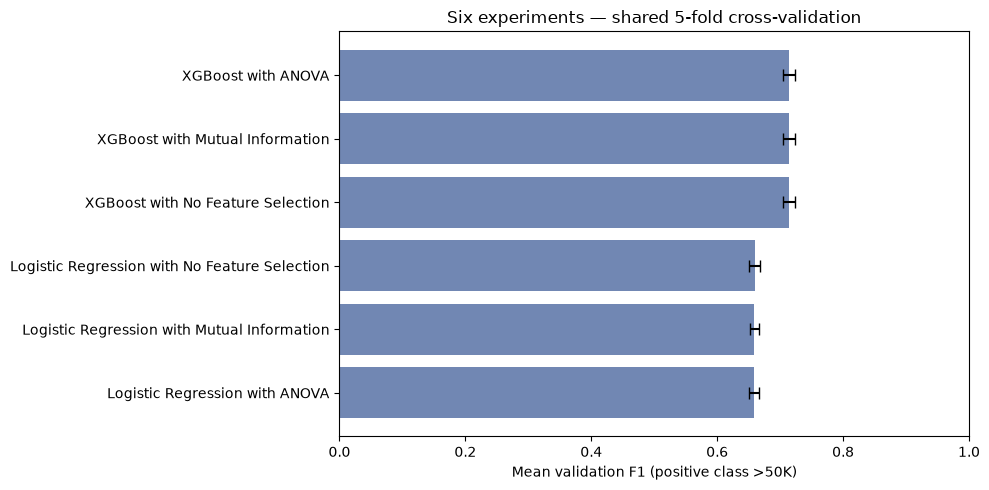

Locked winner selected by mean validation F1: XGBoost with ANOVA
Winner settings: {'feature_select__percentile': 75, 'model__max_depth': 6, 'model__n_estimators': 150}


In [37]:
# 1. Compare the six experiments using their cross-validation results.
# Sort from lowest to highest so the best experiment appears at the top of the graph.
plot_table = cv_results.sort_values("CV F1")

# Create one figure containing one plot.
fig, ax = plt.subplots(1, 1, figsize = (10, 5))   # Create 1 row and 1 column

# Create a horizontal bar chart comparing the six experiments.
ax.barh(
    plot_table["Experiment"],
    plot_table["CV F1"],
    xerr = plot_table["CV F1 SD"],  # Error bars show ±1 standard deviation.
    color = "#7187B3",
    capsize = 4                     # Add small lines at the ends of the error bars.
)

# Add labels and a title to the graph.
ax.set(
    xlim = (0, 1),                   # Lock the horizontal axis from 0 to 1 (prevent auto-zoom)
    xlabel = "Mean validation F1 (positive class >50K)",
    title = "Six experiments — shared 5-fold cross-validation"
)

fig.tight_layout()
plt.show()


# 2. Select the experiment with the highest mean validation F1-score.
# cv_results was already sorted from highest to lowest F1-score in Section 4.4.
winner_name = cv_results.iloc[0]["Experiment"]

# Get the winning Pipeline, which GridSearchCV has already trained on all training data.
winner_pipeline = searches[winner_name].best_estimator_

# 3. Keep the selected model and hyperparameters unchanged before final testing.
print("Locked winner selected by mean validation F1:", winner_name)
print("Winner settings:", searches[winner_name].best_params_)

### 4.6 Compare the Other Validation Metrics

Besides the F1-score, we also compare **precision, recall, specificity, ROC-AUC and accuracy** across all 6 experiments. The table and heatmap below show the **mean validation scores from 5-fold cross-validation** for each experiment. The separate test dataset (`adult.test`) is not used here.

A Seaborn **heatmap** uses colours to show the scores, which makes it easier to compare the experiments across the metrics. Some experiments may do better on certain metrics, but **F1-score remains our main metric for selecting the best model**, as explained in Section 4.3.

,CV F1,CV Precision,CV Recall,CV Specificity,CV ROC-AUC,CV Accuracy
Experiment,,,,,,
XGBoost with ANOVA,0.7140,0.7816,0.6573,0.9417,0.9283,0.8733
XGBoost with Mutual Information,0.7138,0.7828,0.6562,0.9422,0.9284,0.8733
XGBoost with No Feature Selection,0.7138,0.7762,0.6608,0.9396,0.9276,0.8724
Logistic Regression with No Feature Selection,0.6599,0.7348,0.5990,0.9314,0.9048,0.8513
Logistic Regression with Mutual Information,0.6591,0.7347,0.5979,0.9314,0.9047,0.8511
Logistic Regression with ANOVA,0.6591,0.7342,0.5981,0.9312,0.9046,0.8510


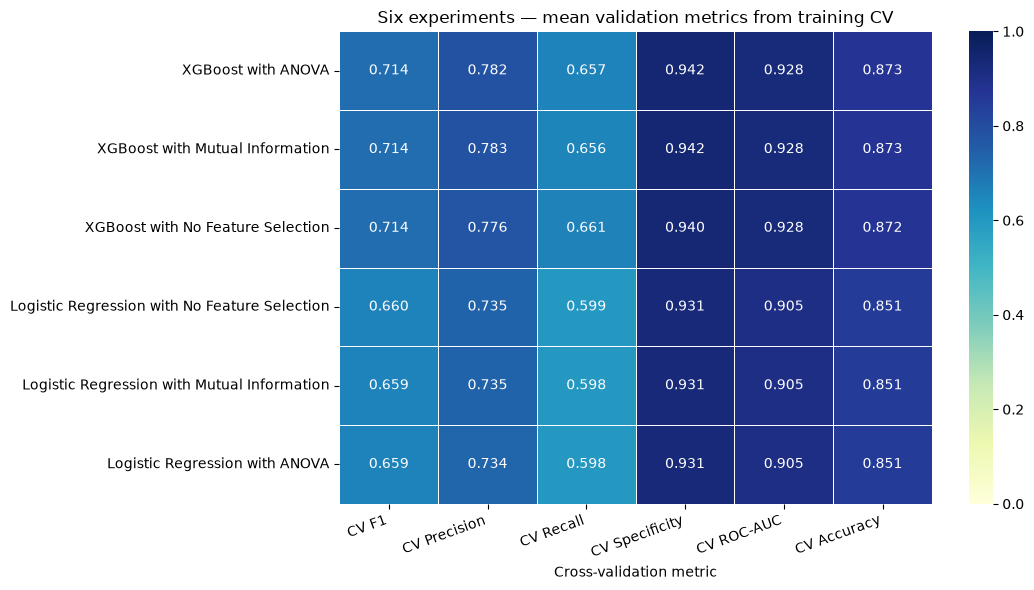

In [38]:
# 1. Select the six cross-validation metrics for comparison.
cv_metric_columns = [
    "CV F1",
    "CV Precision",
    "CV Recall",
    "CV Specificity",
    "CV ROC-AUC",
    "CV Accuracy"
]

# Create a table using the six experiments and their validation scores.
cv_metric_table = cv_results.set_index("Experiment")[cv_metric_columns]

# Display the table rounded to four decimal places.
display(cv_metric_table.round(4))


# 2. Create a heatmap to compare the evaluation metrics.
fig, ax = plt.subplots(1, 1, figsize = (11, 6))   # Create 1 row and 1 column

sns.heatmap(
    cv_metric_table,
    annot = True,      # Display the score inside each box.
    fmt = ".3f",       # Show scores to three decimal places.
    cmap = "YlGnBu",   # Choose the heatmap colour scheme.
    vmin = 0,          # Minimum value on the colour scale.
    vmax = 1,          # Maximum value on the colour scale.
    linewidths = 0.5,
    ax = ax
)

# Add labels and a title.
ax.set(
    title = "Six experiments — mean validation metrics from training CV",
    xlabel = "Cross-validation metric",
    ylabel = ""
)

# Rotate the metric labels slightly so they do not overlap.
ax.set_xticklabels(ax.get_xticklabels(), rotation = 20, ha = "right")
fig.tight_layout()
plt.show()

### 4.7 Logistic Regression training summary

The table below summarises the three Logistic Regression experiments using the validation folds. The differences in F1-score show whether keeping fewer encoded columns helps this model. The final test of the selected model is in Section 5.

In [39]:
# Show the three Logistic Regression experiments separately.
# Keep only the rows where the Model column is Logistic Regression.
lr_cv = cv_results[cv_results['Model'] == 'Logistic Regression']
display(lr_cv[['Experiment', 'CV F1', 'CV F1 SD', 'CV Precision',
               'CV Recall', 'CV ROC-AUC', 'CV Accuracy', 'Best settings']].round(4))

,Experiment,CV F1,CV F1 SD,CV Precision,CV Recall,CV ROC-AUC,CV Accuracy,Best settings
3,Logistic Regression with No Feature Selection,0.6599,0.0087,0.7348,0.5990,0.9048,0.8513,{'model__C': 10.0}
4,Logistic Regression with Mutual Information,0.6591,0.0076,0.7347,0.5979,0.9047,0.8511,"{'feature_select__percentile': 75, 'model__C':..."
5,Logistic Regression with ANOVA,0.6591,0.0080,0.7342,0.5981,0.9046,0.8510,"{'feature_select__percentile': 75, 'model__C':..."


### 4.8 XGBoost training summary

The same validation approach is used for XGBoost. Comparing with the no-feature-selection baseline shows whether ANOVA or MI helps compared with keeping all encoded columns.

In [40]:
# Show the three XGBoost experiments separately.
# Keep only the rows where the Model column is XGBoost.
xgb_cv = cv_results[cv_results['Model'] == 'XGBoost']
display(xgb_cv[['Experiment', 'CV F1', 'CV F1 SD', 'CV Precision',
                'CV Recall', 'CV ROC-AUC', 'CV Accuracy', 'Best settings']].round(4))

,Experiment,CV F1,CV F1 SD,CV Precision,CV Recall,CV ROC-AUC,CV Accuracy,Best settings
0,XGBoost with ANOVA,0.7140,0.0096,0.7816,0.6573,0.9283,0.8733,"{'feature_select__percentile': 75, 'model__max..."
1,XGBoost with Mutual Information,0.7138,0.0095,0.7828,0.6562,0.9284,0.8733,"{'feature_select__percentile': 75, 'model__max..."
2,XGBoost with No Feature Selection,0.7138,0.0097,0.7762,0.6608,0.9276,0.8724,"{'model__max_depth': 6, 'model__n_estimators':..."


## 5. Evaluation

### 5.1 Evaluate and Test the Selected Model

In Sections 4.5 and 4.6, we compared all 6 experiments on Accuracy, Precision, Recall, Specificity, F1-score and ROC-AUC using only the training data and 5-fold cross-validation. We selected the experiment with the highest mean validation F1-score. The selected experiment and its settings are printed in Section 4.5.

GridSearchCV has already retrained the winning Pipeline on the whole training dataset, so we do not need another `.fit()` command. We can directly use `winner_pipeline` for the final test.

We now test only this winner on the original **`adult.test` dataset**. For each test row, `predict_proba()` gives the probability of each class, and `[:, 1]` keeps the probability of earning >50K. We save these probabilities, turn them into class 0 or 1 using our **fixed 0.50 threshold**, and calculate the 6 metrics (Accuracy, Precision, Recall, Specificity, F1-score and ROC-AUC).

| Probability of Earning >50K | Predicted Class |
|:---------------------------:|:---------------:|
| ≥ 0.50 | 1 (>50K)  |
| < 0.50 | 0 (<=50K) |

We calculate the probabilities and predictions **once** and reuse them for the metrics, confusion matrix, ROC curve and demographic audit.

In [41]:
# 1. Prepare the test dataset.
# Use exactly the same predictor columns as the training dataset.
X_test = test_df[feature_columns].copy()  # Keep the original test table unchanged.

# Convert the actual income classes into binary values.
# 0 = <=50K (Negative class)
# 1 = >50K (Positive class)
y_test = (test_df["income"] == ">50K").astype(int)


# 2. Keep sex and race separately for the demographic audit in Section 5.6.
# These are NOT used by the model to predict income.
audit_test = test_df[["sex", "race"]].copy()


# 3. Use the winning model to predict the probability of earning >50K.
# [:, 1] selects the probability of Class 1 for every person.
winner_probability = winner_pipeline.predict_proba(X_test)[:, 1] 

# Why do we use predict_proba() instead of predict()?
# predict() directly returns the predicted class, either 0 or 1.
# predict_proba() returns the probability of each class, which we need for ROC-AUC.


# 4. Convert probabilities into predictions using our fixed threshold.
# Probabilities >= 0.50 become 1, otherwise they become 0.
winner_prediction = (winner_probability >= THRESHOLD).astype(int)


# 5. Display the information about our final evaluation.
print("Selected Experiment:", winner_name)
print("Number of Test Records:", len(X_test))
print("Number of Original Predictors:", X_test.shape[1])

# Display the first 10 predictions for illustration.
prediction_preview = pd.DataFrame({
    "Actual Income": y_test.head(10).values,
    "Probability of >50K": winner_probability[:10],
    "Predicted Income": winner_prediction[:10]
})

display(prediction_preview.round(4))

Selected Experiment: XGBoost with ANOVA
Number of Test Records: 16281
Number of Original Predictors: 11


,Actual Income,Probability of >50K,Predicted Income
0,0,0.0014,0
1,0,0.1786,0
2,1,0.4067,0
3,1,0.9970,1
4,0,0.0003,0
5,0,0.0037,0
6,0,0.0037,0
7,1,0.8940,1
8,0,0.0047,0
9,0,0.0345,0


In [42]:
# 1. Calculate all six evaluation metrics.
# We use the SAME saved predictions and probabilities from above.
test_metrics = {
    "F1": f1_score(
        y_test, winner_prediction, zero_division = "warn"
    ),

    "Precision": precision_score(
        y_test, winner_prediction, zero_division = "warn"
    ),

    "Recall": recall_score(
        y_test, winner_prediction, zero_division = "warn"
    ),

    "Specificity": recall_score(
        y_test, winner_prediction, pos_label = 0, zero_division = "warn"
    ),

    "ROC-AUC": roc_auc_score(
        y_test, winner_probability
    ),

    "Accuracy": accuracy_score(
        y_test, winner_prediction
    )
}


# 2. Convert our results into a pandas DataFrame.
# Only one row is shown because we evaluate only the winning model.
test_results = pd.DataFrame([test_metrics], index = [winner_name])

test_results.index.name = "Selected Experiment"


# 3. Display the final evaluation results.
display(test_results.round(4))

,F1,Precision,Recall,Specificity,ROC-AUC,Accuracy
Selected Experiment,,,,,,
XGBoost with ANOVA,0.7111,0.7745,0.6573,0.9408,0.9277,0.8738


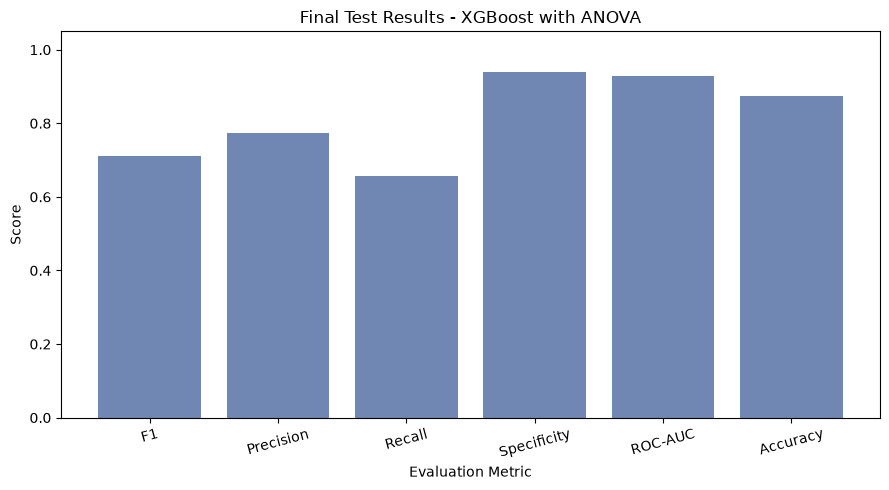

In [43]:
# 1. Get the six scores for our selected model.
scores = test_results.iloc[0]  # Selects the first row of our results table.

# 2. Create a bar chart.
plt.figure(figsize = (9, 5))

plt.bar(
    scores.index,         # Gives the metric names.
    scores.values,        # Gives their numerical scores.
    color = "#7187B3"
)

# 3. Add the title and labels.
plt.title("Final Test Results - " + winner_name)
plt.xlabel("Evaluation Metric")
plt.ylabel("Score")

plt.ylim(0, 1.05)
plt.xticks(rotation = 15)

plt.tight_layout()
plt.show()

### 5.2 Confusion Matrix

A **confusion matrix** shows how many of our selected model's predictions were correct or incorrect. Since this is a binary classification problem, there are four possible outcomes.

|     | Predicted <=50K | Predicted >50K |
|:---:|:---------------:|:--------------:|
| Actual <=50K | True negative (TN) | False positive (FP) |
| Actual >50K | False negative (FN) | True positive (TP) |

**Explanation:**

- **True Negative (TN):** The person actually earns <=50K, and the model correctly predicts <=50K.
- **False Positive (FP):** The person actually earns <=50K, but the model incorrectly predicts >50K.
- **False Negative (FN):** The person actually earns >50K, but the model incorrectly predicts <=50K.
- **True Positive (TP):** The person actually earns >50K, and the model correctly predicts >50K.

The confusion matrix shows which kinds of mistakes our model makes. We reuse the predictions from Section 5.1, so no new predictions are needed.

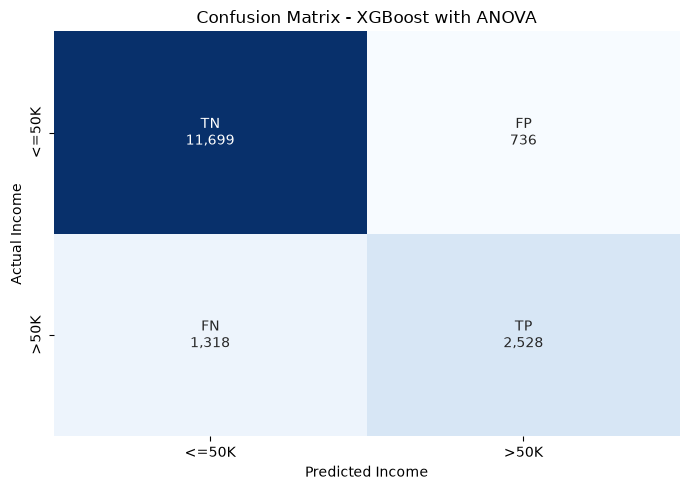

In [44]:
# 1. Calculate the confusion matrix using our saved predictions.
# labels = [0, 1] ensures the class order is consistent.
winner_matrix = confusion_matrix(
    y_test,
    winner_prediction,
    labels = [0, 1]
)


# 2. Create labels showing TN, FP, FN and TP.
cell_labels = [
    [f"TN\n{winner_matrix[0, 0]:,}", f"FP\n{winner_matrix[0, 1]:,}"],
    [f"FN\n{winner_matrix[1, 0]:,}", f"TP\n{winner_matrix[1, 1]:,}"]
]


# 3. Create a heatmap.
plt.figure(figsize = (7, 5))

sns.heatmap(
    winner_matrix,
    annot = cell_labels,   # Display our labels inside each box.
    fmt = "",              # Display the labels as text.
    cmap = "Blues",
    cbar = False,
    xticklabels = ["<=50K", ">50K"],
    yticklabels = ["<=50K", ">50K"]
)


# 4. Add the title and labels.
plt.title("Confusion Matrix - " + winner_name)
plt.xlabel("Predicted Income")
plt.ylabel("Actual Income")

plt.tight_layout()
plt.show()

In [45]:
# Extract the four values from the confusion matrix.
# ravel() converts the 2x2 confusion matrix into an array (row with 4 numbers).
tn, fp, fn, tp = winner_matrix.ravel()

print(f"True Negative (TN): {tn:,}")
print(f"False Positive (FP): {fp:,}")
print(f"False Negative (FN): {fn:,}")
print(f"True Positive (TP): {tp:,}")

True Negative (TN): 11,699
False Positive (FP): 736
False Negative (FN): 1,318
True Positive (TP): 2,528


### 5.3 ROC Curve and ROC-AUC

The **Receiver Operating Characteristic (ROC) curve** shows how well our selected model separates people earning <=50K from people earning >50K at different classification thresholds. The graph uses two measurements.

| Measurement | Meaning |
|:-----------:|:-------:|
| True Positive Rate (TPR) | The proportion of actual >50K cases that are correctly identified. Also known as Recall. |
| False Positive Rate (FPR) | The proportion of actual <=50K cases that are wrongly classified as >50K. Equal to 1 - Specificity. |

The ROC curve plots **TPR against FPR** at different thresholds. **ROC-AUC** is the Area Under the ROC Curve.

- **AUC = 1.0** means the model ranks the two classes perfectly.
- **AUC = 0.5** means the model is no better than random guessing.
- **AUC < 0.5** means the model tends to rank the two classes the wrong way round.

In general, a **higher** ROC-AUC means a **better ability** to separate the two income classes. The diagonal dashed line shows random guessing for comparison. It is not another trained model. Although the ROC curve looks at many thresholds, our final predictions still use the fixed threshold of **0.50**.

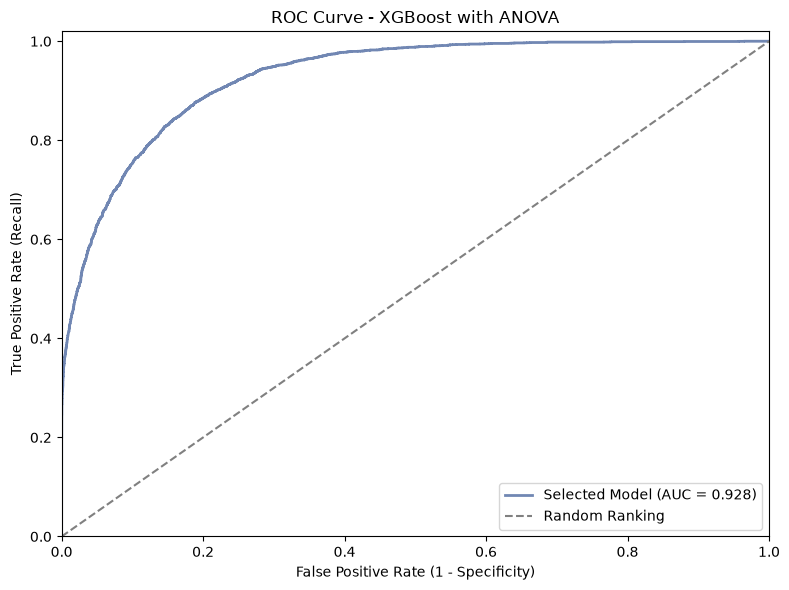

In [46]:
# 1. Calculate the points for the ROC curve.
# We reuse the probabilities calculated in Section 5.1.
false_positive_rate, true_positive_rate, thresholds = roc_curve(
    y_test,
    winner_probability
)

# roc_curve() returns three arrays, the False Positive Rates, the True Positive Rates
# and the classification thresholds used to calculate them.

# 2. Get the ROC-AUC score calculated earlier.
auc_value = test_metrics["ROC-AUC"]    # See Section 5.1


# 3. Plot the ROC curve.
plt.figure(figsize = (8, 6))

plt.plot(
    false_positive_rate,
    true_positive_rate,
    color = "#7187B3",
    linewidth = 2,
    label = f"Selected Model (AUC = {auc_value:.3f})"
)


# 4. Add a diagonal reference line representing random ranking.
plt.plot(
    [0, 1],
    [0, 1],
    linestyle = "--",
    color = "gray",
    label = "Random Ranking"
)


# 5. Add labels and title.
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve - " + winner_name)

plt.xlim(0, 1)
plt.ylim(0, 1.02)

plt.legend(loc = "lower right")

plt.tight_layout()
plt.show()

### 5.4 Examine the Features Retained by Each Experiment

In Section 3, we removed `sex`, `race` and `fnlwgt`, which left **11 original predictors**. However, the number of columns increases after one-hot encoding, because each categorical feature becomes several 0/1 columns. For example, `education` becomes one column for each education level, and a feature with missing values also gets an `Unknown` column.

We tested three feature-selection approaches.

| Feature Selection | Description |
|:-----------------:|:-----------:|
| No Feature Selection | Keep all encoded features, except constant features. |
| ANOVA | Rank the encoded features using F-statistics and keep a selected percentage. |
| Mutual Information | Rank the encoded features using MI scores and keep a selected percentage. |

For ANOVA and Mutual Information, GridSearchCV tested keeping **25%, 50% and 75%** of the encoded features. The final Pipeline also removes constant features using `VarianceThreshold`. Below, we compare how many features each of the six experiments kept and list the features used by our selected model. This uses the models already trained in Section 4. It does not test the other experiments on the test dataset.

In [47]:
# 1. Create a list to store the feature counts.
feature_rows = []


# 2. Examine the features retained by each trained experiment.
for experiment_name, search in searches.items():

    # Get the best trained Pipeline for this experiment.
    fitted_pipeline = search.best_estimator_


    # Get all feature names after preprocessing and one-hot encoding.
    feature_names = fitted_pipeline.named_steps["preprocess"].get_feature_names_out()

    # Count the number of encoded columns before feature selection.
    original_count = len(feature_names)


    # 3. Check whether ANOVA or MI feature selection was used.
    selector = fitted_pipeline.named_steps["feature_select"]

    # If feature selection was used, keep only the selected feature names.
    # "passthrough" means no ranked feature selection was performed.
    if not isinstance(selector, str):                           # A fitted selector is an object, whereas passthrough is text.
        feature_names = feature_names[selector.get_support()]   # get_support() marks the retained columns with True.


    # 4. Remove the names of constant features.
    constant_filter = fitted_pipeline.named_steps["remove_constants"]

    feature_names = feature_names[constant_filter.get_support()]


    # 5. Store the feature counts for this experiment.
    feature_rows.append({
        "Experiment": experiment_name,
        "Encoded Columns Before Selection": original_count,
        "Final Columns Used": len(feature_names)
    })


    # 6. Save the selected feature names of our winning model in memory.
    if experiment_name == winner_name:
        winning_features = feature_names


# 7. Convert the results into a DataFrame.
feature_counts = pd.DataFrame(feature_rows)


# 8. Display the feature counts for all six experiments.
display(feature_counts)


# 9. Display the individual features retained by our selected model.
print("Features Retained by the Selected Model:")

display(pd.DataFrame({
    "Feature": winning_features
}))

,Experiment,Encoded Columns Before Selection,Final Columns Used
0,Logistic Regression with No Feature Selection,100,100
1,Logistic Regression with ANOVA,100,75
2,Logistic Regression with Mutual Information,100,75
3,XGBoost with No Feature Selection,100,100
4,XGBoost with ANOVA,100,75
5,XGBoost with Mutual Information,100,75


Features Retained by the Selected Model:


,Feature
0,age
1,education-num
2,capital-gain
3,capital-loss
4,hours-per-week
...,...
70,native-country_Philippines
71,native-country_Puerto-Rico
72,native-country_Taiwan
73,native-country_United-States


#### 5.4.1 Compare the features retained by ANOVA and MI

This table compares the **actual encoded features** kept by ANOVA and by MI for each model, after refitting on the whole training dataset. The overlap is based on the feature names, not just the number of columns. The lists may differ between Logistic Regression and XGBoost, because GridSearchCV can choose a different percentage for each model.

These refitted feature lists are only for interpretation. The cross-validation scores above were still calculated with feature selection fitted inside each training fold.

In [48]:
# Compare the actual feature names retained after refitting each experiment.
selected_features_by_experiment = {}
for name, fitted_search in searches.items():

    # Get the best Pipeline of this experiment, already refitted on all training data.
    best_pipeline = fitted_search.best_estimator_

    # Start with every encoded column name.
    names = best_pipeline.named_steps['preprocess'].get_feature_names_out()

    # Keep only the columns chosen by ANOVA or MI (skipped when there is no selector).
    selector = best_pipeline.named_steps['feature_select']
    if not isinstance(selector, str):
        names = names[selector.get_support()]

    # Remove the names of constant columns dropped by VarianceThreshold.
    names = names[best_pipeline.named_steps['remove_constants'].get_support()]

    # A set stores unique names so we can compare the selected features.
    selected_features_by_experiment[name] = set(names)

# For two sets, & keeps the names found in both, and - keeps the names found only in the first set.
selection_comparisons = []
for model_name in models:
    anova_name = f'{model_name} with ANOVA'
    mi_name = f'{model_name} with Mutual Information'
    anova_set = selected_features_by_experiment[anova_name]
    mi_set = selected_features_by_experiment[mi_name]
    selection_comparisons.append({
        'Model': model_name,
        'ANOVA columns': len(anova_set),
        'MI columns': len(mi_set),
        'In both': len(anova_set & mi_set),
        'ANOVA only': len(anova_set - mi_set),
        'MI only': len(mi_set - anova_set)
    })

print('Refitted encoded-column overlap (ANOVA vs MI):')
selection_overlap = pd.DataFrame(selection_comparisons)
display(selection_overlap)

Refitted encoded-column overlap (ANOVA vs MI):


,Model,ANOVA columns,MI columns,In both,ANOVA only,MI only
0,Logistic Regression,75,75,74,1,1
1,XGBoost,75,75,74,1,1


### 5.5 Understand Which Features Were Important

After identifying our selected model, we look at which features contributed most to its predictions. Logistic Regression and XGBoost work differently, so they measure feature importance differently.

| Model | Method | Explanation |
|:-----:|:------:|:-----------:|
| Logistic Regression | Coefficients | Show how each feature is associated with the predicted income class. |
| XGBoost | Feature Importance (Gain) | Measures how much a feature improves the model's training objective when it is used to split a decision tree. |

**For Logistic Regression:**

- A positive coefficient increases the predicted log-odds of earning >50K, when the other inputs stay the same.
- A negative coefficient decreases the predicted log-odds of earning >50K.
- A larger absolute coefficient means a stronger association, on the standardised feature scale.

**For XGBoost:**

- A higher gain importance means that the feature contributed more to improving the model's training objective.
- Gain importance does not show whether a feature increases or decreases the probability of earning >50K.

We display the 12 features with the largest coefficients (in absolute value) or the highest gain importance, depending on which model was selected.

Feature importance helps us understand the model, but it does **NOT** prove that these features cause higher or lower income.

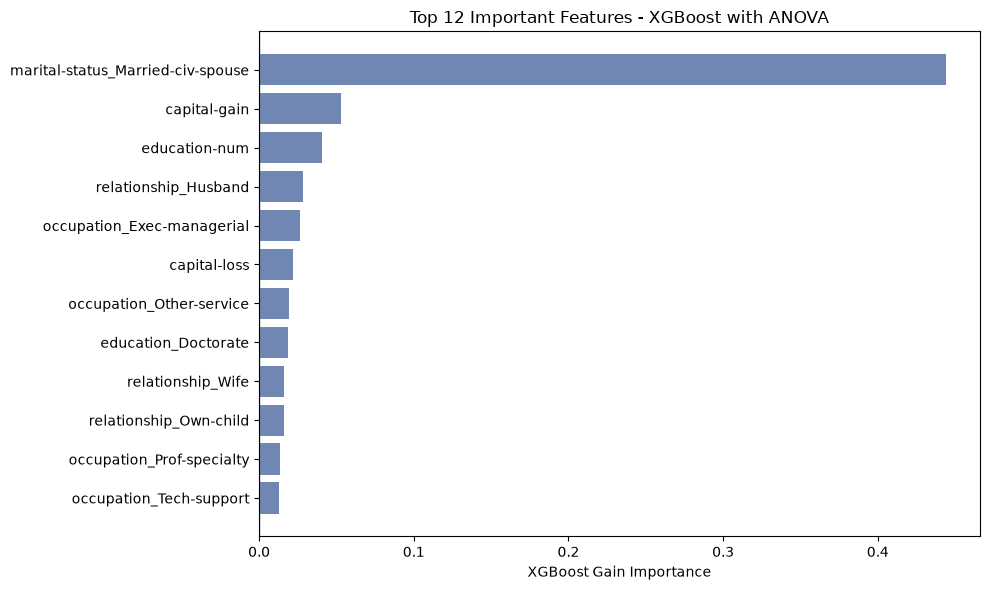

,XGBoost Gain Importance
marital-status_Married-civ-spouse,0.443877
capital-gain,0.053223
education-num,0.040743
relationship_Husband,0.028067
occupation_Exec-managerial,0.026583
capital-loss,0.022036
occupation_Other-service,0.019644
education_Doctorate,0.018666
relationship_Wife,0.016160
relationship_Own-child,0.016047


In [49]:
# 1. Get the trained classifier from our winning Pipeline.
selected_model = winner_pipeline.named_steps["model"]


# 2. Check which type of model won.
if isinstance(selected_model, LogisticRegression):

    # Logistic Regression uses coefficients.
    feature_values = pd.Series(
        selected_model.coef_[0],
        index = winning_features
    )

    # Find the 12 features with the largest absolute coefficients.
    top_names = feature_values.abs().nlargest(12).index

    # Retrieve their original positive or negative values.
    top_features = feature_values.loc[top_names].sort_values()

    x_label = "Logistic Regression Coefficient"


else:

    # XGBoost uses gain-based feature importance.
    feature_values = pd.Series(
        selected_model.feature_importances_,
        index = winning_features
    )

    # Find the 12 most important features.
    top_features = feature_values.nlargest(12).sort_values()

    x_label = "XGBoost Gain Importance"


# 3. Create a horizontal bar chart.
plt.figure(figsize = (10, 6))

plt.barh(
    top_features.index,
    top_features.values,
    color = "#7187B3"
)


# 4. Add the title and labels.
plt.title("Top 12 Important Features - " + winner_name)
plt.xlabel(x_label)

plt.axvline(0, color = "gray", linewidth = 1)

plt.tight_layout()
plt.show()


# 5. Display the numerical values of the top 12 features.
display(top_features.sort_values(ascending = False).to_frame(name = x_label))

### 5.6 Descriptive Audit by Sex and Race

In Section 3, we excluded `sex` and `race` from the predictors, so that our models cannot directly use these sensitive characteristics. **However, removing sensitive features does not guarantee that a model is free from bias.** Other predictors, such as `occupation` and `relationship`, may still be linked to demographic characteristics. Therefore, we carry out a **descriptive demographic audit** on the test dataset.

We compare the following two metrics across the recorded sex and race groups.

| Metric | Explanation |
|:------:|:-----------:|
| True Positive Rate (TPR) | Among people who actually earn >50K, the proportion correctly predicted as >50K. |
| False Positive Rate (FPR) | Among people who actually earn <=50K, the proportion wrongly predicted as >50K. |

We also report the number of people in each group. Differences in TPR or FPR may show differences in model performance that need further investigation. However, this audit cannot prove whether the model is fair or unfair. **Small groups also give less reliable estimates.**

`sex` and `race` are only used for this audit. They are **not used as predictors**, and we do **NOT** change the model based on the audit results. We reuse the predictions from Section 5.1.

Demographic Audit by Sex:


,Characteristic,Group,Number of People,Actually >50K,Actually <=50K,TPR / Recall,FPR
0,sex,Female,5421,590,4831,0.6051,0.0246
1,sex,Male,10860,3256,7604,0.6668,0.0811



Demographic Audit by Race:


,Characteristic,Group,Number of People,Actually >50K,Actually <=50K,TPR / Recall,FPR
2,race,Amer-Indian-Eskimo,159,19,140,0.6842,0.0286
3,race,Asian-Pac-Islander,480,133,347,0.7068,0.0893
4,race,Black,1561,179,1382,0.5754,0.0289
5,race,Other,135,25,110,0.6000,0.0091
6,race,White,13946,3490,10456,0.6599,0.0631


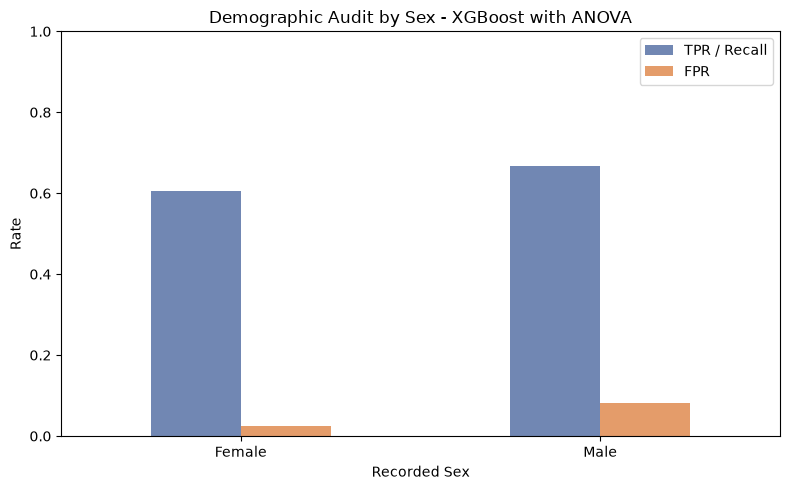

In [50]:
# 1. Create a separate DataFrame for the demographic audit.
# This contains the original sex and race information.
audit_results = audit_test.copy()


# 2. Add the actual income classes and our saved predictions.
audit_results["Actual"] = y_test.to_numpy()

audit_results["Predicted"] = winner_prediction


# 3. Create a list to store the audit results.
audit_rows = []


# 4. Examine sex and race separately.
for characteristic in ["sex", "race"]:

    # groupby() divides the records into demographic groups.
    for group_name, group_data in audit_results.groupby(characteristic, dropna = False):

        # Calculate the confusion matrix for the current group.
        matrix = confusion_matrix(
            group_data["Actual"],
            group_data["Predicted"],
            labels = [0, 1]
        )

        # Extract the four values.
        tn, fp, fn, tp = matrix.ravel()


        # 5. Calculate the True Positive Rate (Recall).
        # TPR = TP / (TP + FN)
        if tp + fn > 0:
            tpr = tp / (tp + fn)

        else:
            tpr = np.nan  # Undefined if nobody in this group earns >50K.


        # 6. Calculate the False Positive Rate.
        # FPR = FP / (FP + TN)
        if fp + tn > 0:
            fpr = fp / (fp + tn)

        else:
            fpr = np.nan  # Undefined if nobody in this group earns <=50K.


        # 7. Store the results for this demographic group.
        audit_rows.append({
            "Characteristic": characteristic,
            "Group": group_name,
            "Number of People": len(group_data),
            "Actually >50K": tp + fn,
            "Actually <=50K": tn + fp,
            "TPR / Recall": tpr,
            "FPR": fpr
        })


# 8. Convert the results into a DataFrame.
audit_table = pd.DataFrame(audit_rows)


# 9. Separate the results by sex and race.
sex_audit = audit_table[audit_table["Characteristic"] == "sex"]

race_audit = audit_table[audit_table["Characteristic"] == "race"]


# 10. Display the results.
print("Demographic Audit by Sex:")
display(sex_audit.round(4))

print("\nDemographic Audit by Race:")
display(race_audit.round(4))


# 11. Create a bar chart comparing TPR and FPR by recorded sex.
sex_audit.plot.bar(
    x = "Group",
    y = ["TPR / Recall", "FPR"],
    figsize = (8, 5),
    color = ["#7187B3", "#E49C6A"],
    rot = 0
)

plt.title("Demographic Audit by Sex - " + winner_name)
plt.xlabel("Recorded Sex")
plt.ylabel("Rate")

plt.ylim(0, 1)

plt.tight_layout()
plt.show()

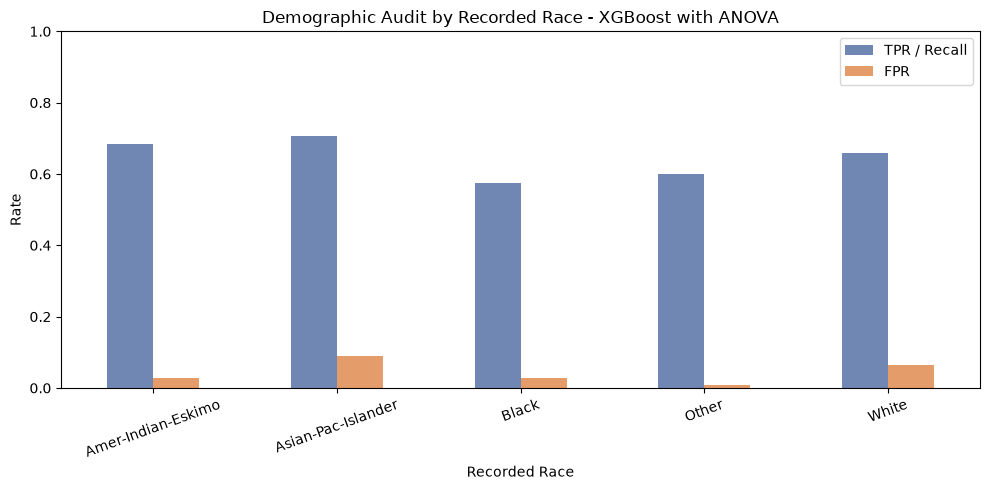

In [51]:
# Also compare the error rates for the recorded race groups.
race_audit.plot.bar(
    x = "Group",
    y = ["TPR / Recall", "FPR"],
    figsize = (10, 5),
    color = ["#7187B3", "#E49C6A"],
    rot = 20
)
plt.title("Demographic Audit by Recorded Race - " + winner_name)
plt.xlabel("Recorded Race")
plt.ylabel("Rate")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

### 5.7 Check for Identical Records Across Training and Test Data

We kept the original UCI Adult training and test datasets throughout the project. However, it is *possible for identical records to appear in **both** datasets*. We therefore check two things.

1. How many test records are identical to a record in the training dataset?
2. How many records are repeated within the test dataset itself?

This check helps us understand a possible limitation of our dataset. Identical records do not necessarily belong to the same person, because the dataset has no unique ID for each person (e.g. an NRIC or Social Security Number).

***Note**: We do **NOT** remove these records, retrain the model or change our final test results based on this check.*

In [52]:
# 1. Remove repeated training rows only for this comparison.
# This does NOT change our original training dataset.
unique_training_rows = train_df.drop_duplicates()


# 2. Find complete test records that also appear in the training data.
# merge() compares all columns shared by both DataFrames.
# how = "inner" keeps only matching records/rows.
matching_rows = test_df.merge(unique_training_rows, how = "inner")

# 3. Count repeated complete records within the test dataset.
repeated_test_rows = test_df.duplicated().sum()


# 4. Display the results.
print("Test records matching training records:", len(matching_rows))

print("Repeated records within the test dataset:", repeated_test_rows)

Test records matching training records: 23
Repeated records within the test dataset: 5


### 5.8 Summary of Findings

In Section 4, we compared 6 experiments using Stratified 5-Fold Cross-Validation and selected the experiment with the highest mean validation F1-score. In Section 5, we tested only that selected model on the separate test dataset. Our final evaluation includes Accuracy, Precision, Recall, Specificity, F1-score, ROC-AUC and the confusion matrix.

We also examined the features kept by the models and carried out a descriptive demographic audit to compare error rates across the recorded `sex` and `race` groups.

#### 5.8.1 Compare feature selection with the same-model baseline

To see whether feature selection improved performance, we compare ANOVA and Mutual Information with the same model without feature selection. We compare the **mean cross-validation F1-scores** from Section 4, not the F1-score on the test dataset.

| Change in CV F1 Score | Interpretation |
|:---------------------:|:--------------:|
| Positive | Feature selection achieved a higher mean validation F1-score than no feature selection. |
| Negative | Feature selection achieved a lower mean validation F1-score than no feature selection. |
| Close to zero | Both approaches achieved similar validation performance. |

A slightly higher mean validation F1-score does not guarantee that a method will always perform better, especially when the difference is small, because performance varies across the validation folds.

We use these results to discuss whether feature selection improved performance or reduced the number of features our models need. Feature selection can still be useful when the F1-score does not improve, as long as it removes many features without clearly lowering performance.

In [53]:
# 1. Get the cross-validation results for our selected experiment.
winner_cv = cv_results[
    cv_results["Experiment"] == winner_name
].iloc[0]


# 2. Display the selected model and its best hyperparameters.
print("FINAL SELECTED MODEL")
print("--------------------")

print("Selected Experiment:", winner_name)

print("Best Hyperparameters:", searches[winner_name].best_params_)


# 3. Display the training cross-validation results.
print("\nCROSS-VALIDATION RESULTS")
print("------------------------")

print(f"Mean Validation F1: {winner_cv['CV F1']:.4f}")
print(f"Validation F1 Standard Deviation: {winner_cv['CV F1 SD']:.4f}")


# 4. Display the final test results.
print("\nFINAL TEST RESULTS")
print("------------------")

for metric, value in test_metrics.items():
    print(f"{metric}: {value:.4f}")


# 5. Compare feature selection against no feature selection.
comparison_rows = []

for model_name in models:

    # Get the three experiments belonging to the current model.
    model_results = cv_results[cv_results["Model"] == model_name]


    # Get the CV F1-score without feature selection.
    no_selection_f1 = model_results[
        model_results["Selection"] == "None"
    ]["CV F1"].iloc[0]


    # Compare ANOVA and MI against the same model without selection.
    for selection_name in ["ANOVA", "Mutual Information"]:

        # Get the CV F1-score with the current feature-selection method.
        selected_f1 = model_results[
            model_results["Selection"] == selection_name
        ]["CV F1"].iloc[0]


        # Calculate the difference in validation F1.
        f1_difference = selected_f1 - no_selection_f1


        # Store the comparison.
        comparison_rows.append({
            "Model": model_name,
            "Feature Selection": selection_name,
            "Without Selection F1": no_selection_f1,
            "With Selection F1": selected_f1,
            "Change in CV F1": f1_difference
        })


# 6. Convert the comparison results into a DataFrame.
comparison_table = pd.DataFrame(comparison_rows)


# 7. Display the comparison.
print("\nFEATURE SELECTION COMPARISON")
print("----------------------------")

display(comparison_table.round(4))

FINAL SELECTED MODEL
--------------------
Selected Experiment: XGBoost with ANOVA
Best Hyperparameters: {'feature_select__percentile': 75, 'model__max_depth': 6, 'model__n_estimators': 150}

CROSS-VALIDATION RESULTS
------------------------
Mean Validation F1: 0.7140
Validation F1 Standard Deviation: 0.0096

FINAL TEST RESULTS
------------------
F1: 0.7111
Precision: 0.7745
Recall: 0.6573
Specificity: 0.9408
ROC-AUC: 0.9277
Accuracy: 0.8738

FEATURE SELECTION COMPARISON
----------------------------


,Model,Feature Selection,Without Selection F1,With Selection F1,Change in CV F1
0,Logistic Regression,ANOVA,0.6599,0.6591,-0.0008
1,Logistic Regression,Mutual Information,0.6599,0.6591,-0.0007
2,XGBoost,ANOVA,0.7138,0.7140,0.0003
3,XGBoost,Mutual Information,0.7138,0.7138,0.0000


### 5.9 Limitations and Possible Improvements

Although we compared 6 experiments and selected the model with the highest mean validation F1-score, our project has several limitations.

**1. Limited Hyperparameter Tuning**

We tested a limited number of hyperparameter combinations for Logistic Regression and XGBoost. Therefore, our selected model is the best among the configurations we tested, but it may not be the best possible model.

***Possible Improvement:** Explore a wider range of hyperparameters using cross-validation on the training data.*

**2. Limitations of Feature Selection**

ANOVA and Mutual Information score each feature on its own when ranking them, so they may not fully capture interactions between several features. In addition, the MI scores depend on our choice of which features are treated as discrete or continuous. Selecting fewer features also does not always improve model performance.

***Possible Improvement:** Explore other feature-selection methods and compare their performance and feature counts.*

**3. Overlapping Education Features**

`education` and `education-num` contain very similar information, as both describe a person's education level. The model may split the importance between them, so their feature importance should be interpreted with care. Feature importance also does not show that education directly causes higher income.

***Possible Improvement:** Compare the results after keeping only one of the two education features.*

**4. Optimistic Validation Scores and Small Differences**

We used the same 5 folds both to choose the hyperparameters and to choose the best experiment. Therefore, the mean validation F1-score of our selected model may be slightly optimistic. In addition, the 3 XGBoost experiments achieved very similar mean validation F1-scores, and the differences between them are much smaller than their standard deviations across the folds. These differences are too small to show that one experiment is truly better, and a different computer or random seed may rank them in a different order. The separate test dataset, which was not used for any decisions, gives an independent final check.

***Possible Improvement:** Use nested cross-validation, or repeat the cross-validation with different random seeds, to check whether the ranking stays the same.*

**5. Historical Dataset**

The UCI Adult dataset contains historical US census information and uses a fixed USD \$50,000 threshold. Therefore, our findings may not represent income patterns in today's society or in other countries such as Singapore.

***Possible Improvement:** Evaluate the selected model on a newer, independent dataset.*

**6. Class Imbalance**

The dataset contains more people earning <=50K than >50K. This may affect model performance, especially when identifying the smaller >50K class. We selected models using the F1-score, but different applications may need a different balance between false positives and false negatives.

***Possible Improvement:** Investigate class weights, SMOTE or a different classification threshold, applied inside the training folds only, so that no information leaks from the validation data.*

**7. One `Unknown` Category for All Missing Values**

We placed all missing `workclass`, `occupation` and `native-country` values into one `Unknown` category, because people with a missing workclass or occupation earn >50K much less often than others (Section 2.4). However, this treats every missing value the same way, even though values may be missing for different reasons.

***Possible Improvement:** Compare this approach with other ways of handling missing values, such as filling them with the most common category, using cross-validation on the training data.*

**8. Potential Demographic Bias**

Although we excluded `sex` and `race` from the model inputs, other features, such as `relationship`, may still be linked to demographic characteristics. Our demographic audit shows differences in error rates, but it does not guarantee fairness. Some groups are also small (e.g. 159 people in Amer-Indian-Eskimo and 135 in Other), so their error rates are less reliable.

***Possible Improvement:** Carry out more complete fairness assessments using suitable methods and independent data.*

**9. Possible Matching Records**

23 test records are identical to records in the training dataset, and 5 records are repeated within the test dataset (see Section 5.7). Since the dataset has no unique IDs, we cannot tell whether these records belong to the same person. If they do, the test results may be slightly optimistic.

***Possible Improvement:** Repeat the final test with these records removed and report both results, without changing the selected model.*

### 5.10 Final conclusion

We compared Logistic Regression and XGBoost with three feature-selection approaches, using the same stratified five folds for every experiment. The final model was chosen using the mean validation F1-score, before the test dataset was used. The conclusion below is generated from the current run, so the model name and results always match the tables above.

In [54]:
# Summarise the results from this run without hard-coding a winner or scores.
winner_feature_count = feature_counts.loc[
    feature_counts["Experiment"] == winner_name, "Final Columns Used"
].iloc[0]

conclusion = (
    f"**{winner_name}** achieved the highest mean validation F1 among our tested experiments "
    f"({winner_cv['CV F1']:.4f}, with fold SD {winner_cv['CV F1 SD']:.4f}). "
    f"Its refitted pipeline retained **{winner_feature_count} encoded inputs**. "
    f"On the separate test set, its F1 was **{test_metrics['F1']:.4f}**, "
    f"precision was {test_metrics['Precision']:.4f}, recall was {test_metrics['Recall']:.4f}, "
    f"and ROC-AUC was {test_metrics['ROC-AUC']:.4f}. "
    "These results provide an educational comparison of income classifiers on historical US data. "
    "They do not establish suitability for present-day decisions or guarantee fairness."
)
display(Markdown(conclusion))

# A positive change means a higher CV F1, and a negative change means a lower CV F1.
for _, row in comparison_table.iterrows():
    print(
        f"{row['Model']} with {row['Feature Selection']}: "
        f"change from its baseline = {row['Change in CV F1']:+.4f} F1 points."
    )
print("Small differences may reflect variation between validation folds.")

**XGBoost with ANOVA** achieved the highest mean validation F1 among our tested experiments (0.7140, with fold SD 0.0096). Its refitted pipeline retained **75 encoded inputs**. On the separate test set, its F1 was **0.7111**, precision was 0.7745, recall was 0.6573, and ROC-AUC was 0.9277. These results provide an educational comparison of income classifiers on historical US data. They do not establish suitability for present-day decisions or guarantee fairness.

Logistic Regression with ANOVA: change from its baseline = -0.0008 F1 points.
Logistic Regression with Mutual Information: change from its baseline = -0.0007 F1 points.
XGBoost with ANOVA: change from its baseline = +0.0003 F1 points.
XGBoost with Mutual Information: change from its baseline = +0.0000 F1 points.
Small differences may reflect variation between validation folds.


#### 5.10.1 Our machine learning workflow

`Data Loading and CSV Export` → `Training-Data EDA` → `Data Preprocessing` → `6 Experiments with 5-Fold CV and Hyperparameter Tuning` → `Select Best Model` → `Final Test Evaluation` → `Results and Analysis`

### 5.11 Q&A for viva

| Question | Answer |
|:--------:|---|
| Why is this classification? | We predict one of two income categories, not an exact salary. |
| Why save CSV files? | They are plain-text tables that JupyterLab can preview directly. Separate training and test files keep the original split. |
| Why not scale everything before CV? | That would let the validation rows influence the preprocessing. Our Pipeline learns each step only from the training folds. |
| Why five-fold CV? | Each training row is used for validation once, while a separate test set stays untouched. |
| Why use F1? | We want to balance precision and recall for the smaller >50K class. We also report the other metrics. |
| Why do the two models have different hyperparameters? | Logistic Regression and XGBoost have different settings. We still use the same data, folds and metric, and test 4 combinations for each model. |
| Did feature selection help? | Mainly by reducing the number of inputs. In our run, ANOVA and MI kept 75 of the 100 encoded columns (25% fewer) while achieving almost the same mean validation F1-score (Sections 5.4 and 5.8.1). The change in F1 is much smaller than the variation between folds, so we cannot claim that feature selection truly improved F1. |
| How is the winner chosen? | We compare each experiment's best mean validation F1-score. Only the overall winner is tested. |
| Do we tune the winner again? | No. GridSearchCV already chose its settings and refitted it on all the training rows. |
| Why several final charts if the model is tested once? | The metric table, confusion matrix, ROC curve and audit all reuse one saved set of predictions. |
| Why put missing categories into a separate `Unknown` category? | People with a missing workclass or occupation earn >50K much less often than others (Section 2.4). Keeping them as `Unknown` lets the model use this pattern instead of hiding it, and every row is kept. |
| Why keep education-num numerical? | It is a numerical code for education level. Only text categories, such as education, are one-hot encoded. |
| Why scale the one-hot columns too? | Our Pipeline scales every input for Logistic Regression, so that regularisation treats all inputs on a similar scale. XGBoost skips scaling. |
| Why remove `sex`, `race` and `fnlwgt`? | We do not use sensitive demographic attributes as direct inputs, and `fnlwgt` is a survey weight rather than a personal characteristic. Sex and race are still used for the audit. |
| What does `n_jobs = -2` mean? | It uses all available CPU cores except one, with at least one worker. |
| Do different demographic error rates prove discrimination? | No. They describe this dataset and must be read together with the group sizes and other limitations. |
| Does the exploratory feature ranking leak into CV? | No. That ranking is not reused. Each CV pipeline learns a fresh ranking from its own training folds. |

### 5.12 Sources and acknowledgements

[1] B. Becker and R. Kohavi, "Adult," *UCI Machine Learning Repository*, 1996, doi: 10.24432/C5XW20. Available: https://archive.ics.uci.edu/dataset/2/adult

[2] scikit-learn developers, "Common pitfalls and recommended practices," *scikit-learn Documentation*. Accessed: Nov. 17, 2026. [Online]. Available: https://scikit-learn.org/stable/common_pitfalls.html 

[3] scikit-learn developers, "LogisticRegression," *scikit-learn Documentation*. Accessed: Nov. 17, 2026. [Online]. Available: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

[4] scikit-learn developers, "OneHotEncoder," *scikit-learn Documentation*. Accessed: Nov. 17, 2026. [Online]. Available: https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html

[5] scikit-learn developers, "Pipeline," *scikit-learn Documentation*. Accessed: Nov. 17, 2026. [Online]. Available: https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html

[6] scikit-learn developers, "f_classif," *scikit-learn Documentation*. Accessed: Nov. 17, 2026. [Online]. Available: https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.f_classif.html 

[7] scikit-learn developers, "mutual_info_classif," *scikit-learn Documentation*. Accessed: Nov. 17, 2026. [Online]. Available: https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.mutual_info_classif.html

[8] scikit-learn developers, "StratifiedKFold," *scikit-learn Documentation*. Accessed: Nov. 17, 2026. [Online]. Available: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html 

[9] scikit-learn developers, "GridSearchCV," *scikit-learn Documentation*. Accessed: Nov. 17, 2026. [Online]. Available: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html

[10] XGBoost developers, "Python API Reference," *XGBoost Documentation*. Accessed: Nov. 17, 2026. [Online]. Available: https://xgboost.readthedocs.io/en/stable/python/python_api.html 

[11] XGBoost developers, "XGBoost Parameters," *XGBoost Documentation*. Accessed: Nov. 17, 2026. [Online]. Available: https://xgboost.readthedocs.io/en/stable/parameter.html

### 5.13 AI assistance and declaration

ChatGPT were used to assist with code development, comments, explanations and execution checks. All outputs were reviewed and verified by group members, who made revisions where necessary. The overall workflow, concepts and methodologies were independently determined by the group.